In [ ]:
# Locate the repository when running from any notebook subfolder.
from pathlib import Path
import os
_notebook_start = Path.cwd().resolve()
_notebook_root = next(
    (p for p in [_notebook_start, *_notebook_start.parents]
     if (p / "docs" / "predictor_list.csv").is_file()
     and (p / "notebooks").is_dir()), None
)
if _notebook_root is None:
    raise FileNotFoundError("Cannot locate the project repository.")
os.chdir(_notebook_root)


# INMET Weather Data Preparation

This notebook inspects external INMET weather observations
for 2016–2018 and prepares them for order-level analysis.

Station coverage, timestamps, missing values, and measurement
definitions are checked before aggregation and joining.

Weather at dispatch and receipt will support retrospective
analysis. Predictor eligibility will be reviewed separately
against the agreed prediction cutoff.

In [1]:
from pathlib import Path
import zipfile
import pandas as pd

current_dir = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        path
        for path in [current_dir, *current_dir.parents]
        if (path / "data/processed/research_data.csv").is_file()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Cannot locate the project root.")

ZIP_PATH = (
    PROJECT_ROOT / "data/external/inmet/raw/2017.zip"
)

assert ZIP_PATH.is_file()
assert zipfile.is_zipfile(ZIP_PATH)

print("Archive:", ZIP_PATH)

Archive: D:\Group5_STAT3013_EDA\data\external\inmet\raw\2017.zip


In [2]:
station_rows = []
metadata_errors = []

with zipfile.ZipFile(ZIP_PATH) as archive:
    csv_files = sorted(
        name
        for name in archive.namelist()
        if name.lower().endswith(".csv")
    )

    for filename in csv_files:
        try:
            with archive.open(filename) as stream:
                header_bytes = b"".join(
                    stream.readline() for _ in range(20)
                )

            try:
                header_text = header_bytes.decode("utf-8-sig")
                encoding = "utf-8-sig"
            except UnicodeDecodeError:
                header_text = header_bytes.decode("latin-1")
                encoding = "latin-1"

            lines = header_text.splitlines()

            header_position = next(
                (
                    index
                    for index, line in enumerate(lines)
                    if line.split(";")[0].strip().upper().startswith("DATA")
                    and "HORA" in line.upper()
                ),
                None,
            )

            if header_position is None:
                raise ValueError(
                    "No date/hour header found in the first 20 lines."
                )

            metadata = {}

            for line in lines[:header_position]:
                if ";" in line:
                    key, value = line.split(";", 1)
                    key = key.strip().rstrip(":").strip()
                    metadata[key] = value.strip()

            columns = [
                value.strip()
                for value in lines[header_position].split(";")
            ]

            while columns and columns[-1] == "":
                columns.pop()

            station_rows.append({
                "file": filename,
                "state": metadata.get("UF"),
                "station_code": metadata.get("CODIGO (WMO)"),
                "station_name": metadata.get("ESTAÇÃO"),
                "latitude": metadata.get("LATITUDE"),
                "longitude": metadata.get("LONGITUDE"),
                "header_line": header_position + 1,
                "column_count": len(columns),
                "encoding": encoding,
            })

        except Exception as error:
            metadata_errors.append({
                "file": filename,
                "error": str(error),
            })

assert station_rows, "No station metadata could be read."

station_inventory = pd.DataFrame(station_rows)

state_inventory = (
    station_inventory
    .groupby("state", dropna=False)
    .agg(
        csv_files=("file", "size"),
        station_codes=("station_code", "nunique"),
    )
    .reset_index()
)

print("ARCHIVE METADATA SUMMARY")
print("CSV files:", len(csv_files))
print("Metadata rows read:", len(station_inventory))
print("Files with errors:", len(metadata_errors))
print(
    "Unique station codes:",
    station_inventory["station_code"].nunique(),
)
print(
    "Missing state:",
    int(station_inventory["state"].isna().sum()),
)
print(
    "Missing station code:",
    int(station_inventory["station_code"].isna().sum()),
)

print("\nSTATIONS BY STATE")
display(state_inventory)

print("\nHEADER STRUCTURES")
display(
    station_inventory[
        ["header_line", "column_count", "encoding"]
    ]
    .value_counts(dropna=False)
    .rename("files")
    .reset_index()
)

if metadata_errors:
    print("\nMETADATA ERRORS")
    display(pd.DataFrame(metadata_errors))

ARCHIVE METADATA SUMMARY
CSV files: 563
Metadata rows read: 563
Files with errors: 0
Unique station codes: 563
Missing state: 0
Missing station code: 0

STATIONS BY STATE


,state,csv_files,station_codes
0,AC,7,7
1,AL,7,7
2,AM,25,25
3,AP,3,3
4,BA,46,46
5,CE,14,14
6,DF,5,5
7,ES,13,13
8,GO,24,24
9,MA,17,17



HEADER STRUCTURES


,header_line,column_count,encoding,files
0,9,19,latin-1,563


## Hourly Observation Quality

Each station file is inspected separately for timestamp
validity, duplicate records, calendar coverage, and
meteorological missing values.

Calendar coverage and measurement availability are
reported separately. Missing observations are retained.
No daily aggregation or order-level join is performed.

In [3]:
import numpy as np

expected_hours = pd.date_range(
    "2017-01-01 00:00",
    "2017-12-31 23:00",
    freq="h",
    tz="UTC",
)

station_quality_rows = []
variable_quality_rows = []
observation_errors = []
reference_columns = None

with zipfile.ZipFile(ZIP_PATH) as archive:
    for number, station in enumerate(
        station_inventory.itertuples(index=False),
        start=1,
    ):
        try:
            with archive.open(station.file) as stream:
                hourly = pd.read_csv(
                    stream,
                    sep=";",
                    skiprows=int(station.header_line) - 1,
                    encoding=station.encoding,
                    dtype="string",
                    keep_default_na=False,
                )

            hourly.columns = hourly.columns.str.strip()

            empty_extra_columns = [
                column
                for column in hourly.columns
                if column.startswith("Unnamed:")
                and hourly[column].str.strip().eq("").all()
            ]

            hourly = hourly.drop(columns=empty_extra_columns)

            # Check names and order, not just the column count.
            if reference_columns is None:
                reference_columns = hourly.columns.tolist()

            if hourly.columns.tolist() != reference_columns:
                raise ValueError("Column names or order differ.")

            timestamps = pd.to_datetime(
                hourly["DATA (YYYY-MM-DD)"].str.strip()
                + " "
                + hourly["HORA (UTC)"].str.strip(),
                format="%Y-%m-%d %H:%M",
                errors="coerce",
                utc=True,
            )

            valid_times = timestamps.dropna()
            unique_times = pd.DatetimeIndex(valid_times.unique())

            file_quality_rows = []

            for column in hourly.columns[2:]:
                original = hourly[column].str.strip()

                numeric = pd.to_numeric(
                    original.replace("", pd.NA).str.replace(
                        ",", ".", regex=False
                    ),
                    errors="coerce",
                )

                blank = original.eq("")
                missing_code = numeric.eq(-9999)
                unparsed = original.ne("") & numeric.isna()
                nonfinite = numeric.notna() & ~np.isfinite(numeric)

                usable = numeric.mask(missing_code | nonfinite)

                file_quality_rows.append({
                    "file": station.file,
                    "state": station.state,
                    "station_code": station.station_code,
                    "variable": column,
                    "rows": len(hourly),
                    "blank": int(blank.sum()),
                    "code_minus9999": int(missing_code.sum()),
                    "unparsed": int(unparsed.sum()),
                    "nonfinite": int(nonfinite.sum()),
                    "available": int(usable.notna().sum()),
                    "minimum": usable.min(),
                    "maximum": usable.max(),
                })

            station_quality_rows.append({
                "state": station.state,
                "station_code": station.station_code,
                "rows": len(hourly),
                "invalid_timestamps": int(timestamps.isna().sum()),
                "duplicate_timestamps": int(
                    valid_times.duplicated().sum()
                ),
                "hours_outside_calendar_grid": int(
                    (~valid_times.isin(expected_hours)).sum()
                ),
                "unrecorded_calendar_hours": len(
                    expected_hours.difference(unique_times)
                ),
                "first_timestamp": valid_times.min(),
                "last_timestamp": valid_times.max(),
            })

            variable_quality_rows.extend(file_quality_rows)

        except Exception as error:
            observation_errors.append({
                "file": station.file,
                "error": str(error),
            })

        if number % 50 == 0 or number == len(station_inventory):
            print(
                f"Inspected {number}/{len(station_inventory)} files"
            )

assert station_quality_rows, "No station files were processed."

station_quality = pd.DataFrame(station_quality_rows)
variable_quality = pd.DataFrame(variable_quality_rows)

variable_overview = (
    variable_quality
    .groupby("variable")
    .agg(
        station_files=("file", "nunique"),
        recorded_rows=("rows", "sum"),
        blank=("blank", "sum"),
        code_minus9999=("code_minus9999", "sum"),
        unparsed=("unparsed", "sum"),
        nonfinite=("nonfinite", "sum"),
        available=("available", "sum"),
        minimum=("minimum", "min"),
        maximum=("maximum", "max"),
    )
    .reset_index()
)

variable_overview["unavailable_percent"] = (
    (
        variable_overview["recorded_rows"]
        - variable_overview["available"]
    )
    / variable_overview["recorded_rows"]
    * 100
)

print("\nARCHIVE OBSERVATION SUMMARY")
print("Files processed:", len(station_quality))
print("Files with errors:", len(observation_errors))
print("Total rows:", int(station_quality["rows"].sum()))
print(
    "Invalid timestamps:",
    int(station_quality["invalid_timestamps"].sum()),
)
print(
    "Duplicate timestamps:",
    int(station_quality["duplicate_timestamps"].sum()),
)
print(
    "Timestamps outside the calendar grid:",
    int(station_quality["hours_outside_calendar_grid"].sum()),
)
print(
    "Stations with all 8,760 calendar hours recorded:",
    int(station_quality["unrecorded_calendar_hours"].eq(0).sum()),
)

print("\nVARIABLE QUALITY OVERVIEW")
display(variable_overview.round(2))

print("\nFIRST 10 STATIONS WITH UNRECORDED CALENDAR HOURS")
display(
    station_quality.loc[
        station_quality["unrecorded_calendar_hours"] > 0
    ].head(10)
)

if observation_errors:
    print("\nFILES REQUIRING REVIEW")
    display(pd.DataFrame(observation_errors))

Inspected 50/563 files
Inspected 100/563 files
Inspected 150/563 files
Inspected 200/563 files
Inspected 250/563 files
Inspected 300/563 files
Inspected 350/563 files
Inspected 400/563 files
Inspected 450/563 files
Inspected 500/563 files
Inspected 550/563 files
Inspected 563/563 files

ARCHIVE OBSERVATION SUMMARY
Files processed: 563
Files with errors: 0
Total rows: 4775544
Invalid timestamps: 0
Duplicate timestamps: 0
Timestamps outside the calendar grid: 0
Stations with all 8,760 calendar hours recorded: 529

VARIABLE QUALITY OVERVIEW


,variable,station_files,recorded_rows,blank,code_minus9999,unparsed,nonfinite,available,minimum,maximum,unavailable_percent
0,"PRECIPITAÇÃO TOTAL, HORÁRIO (mm)",563,4775544,0,734336,0,0,4041208,0.0,88.2,15.38
1,"PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORAR...",563,4775544,0,514039,0,0,4261505,727.1,1046.8,10.76
2,PRESSÃO ATMOSFERICA MAX.NA HORA ANT. (AUT) (mB),563,4775544,0,514641,0,0,4260903,729.7,1048.1,10.78
3,PRESSÃO ATMOSFERICA MIN. NA HORA ANT. (AUT) (mB),563,4775544,0,515041,0,0,4260503,727.0,1045.5,10.78
4,RADIACAO GLOBAL (KJ/m²),563,4775544,0,2406895,0,0,2368649,0.0,7053.1,50.40
5,"TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)",563,4775544,0,498196,0,0,4277348,-8.0,44.3,10.43
6,TEMPERATURA DO PONTO DE ORVALHO (°C),563,4775544,0,581177,0,0,4194367,-42.5,33.2,12.17
7,TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C),563,4775544,0,501228,0,0,4274316,-7.6,44.4,10.50
8,TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C),563,4775544,0,501338,0,0,4274206,-9.8,40.3,10.50
9,TEMPERATURA ORVALHO MAX. NA HORA ANT. (AUT) (°C),563,4775544,0,587840,0,0,4187704,-35.0,36.3,12.31



FIRST 10 STATIONS WITH UNRECORDED CALENDAR HOURS


,state,station_code,rows,invalid_timestamps,duplicate_timestamps,hours_outside_calendar_grid,unrecorded_calendar_hours,first_timestamp,last_timestamp
1,DF,A042,3984,0,0,0,4776,2017-07-19 00:00:00+00:00,2017-12-31 23:00:00+00:00
4,DF,A047,7872,0,0,0,888,2017-02-07 00:00:00+00:00,2017-12-31 23:00:00+00:00
21,GO,A029,3072,0,0,0,5688,2017-08-26 00:00:00+00:00,2017-12-31 23:00:00+00:00
22,GO,A031,4464,0,0,0,4296,2017-06-29 00:00:00+00:00,2017-12-31 23:00:00+00:00
67,MT,A911,1752,0,0,0,7008,2017-10-20 00:00:00+00:00,2017-12-31 23:00:00+00:00
78,MT,A923,1608,0,0,0,7152,2017-10-26 00:00:00+00:00,2017-12-31 23:00:00+00:00
99,AL,A371,2472,0,0,0,6288,2017-09-20 00:00:00+00:00,2017-12-31 23:00:00+00:00
185,PB,A373,1416,0,0,0,7344,2017-11-03 00:00:00+00:00,2017-12-31 23:00:00+00:00
198,PE,A370,2592,0,0,0,6168,2017-09-15 00:00:00+00:00,2017-12-31 23:00:00+00:00
226,RN,A372,1296,0,0,0,7464,2017-11-08 00:00:00+00:00,2017-12-31 23:00:00+00:00


## Cross-Year Format Inspection

Sample station files from 2016 and 2018 are inspected
before applying a common reader across all three years.

The inspection checks encoding, metadata layout,
column names, and date/hour formats.

In [4]:
cross_year_preview_rows = []

for year in [2016, 2018]:
    year_zip_path = (
        PROJECT_ROOT
        / "data"
        / "external"
        / "inmet"
        / "raw"
        / f"{year}.zip"
    )

    assert year_zip_path.is_file(), f"Missing archive: {year}"
    assert zipfile.is_zipfile(year_zip_path), (
        f"Unreadable ZIP archive: {year}"
    )

    with zipfile.ZipFile(year_zip_path) as archive:
        year_csv_files = sorted(
            name
            for name in archive.namelist()
            if name.lower().endswith(".csv")
        )

        assert year_csv_files, f"No CSV files found for {year}"

        # Prefer the same station inspected in 2017.
        matching_station_files = [
            name
            for name in year_csv_files
            if "_A701_" in name.upper()
        ]

        sample_filename = (
            matching_station_files[0]
            if matching_station_files
            else year_csv_files[0]
        )

        sample_bytes = archive.read(sample_filename)

    try:
        sample_text = sample_bytes.decode("utf-8-sig")
        sample_encoding = "utf-8-sig"
    except UnicodeDecodeError:
        sample_text = sample_bytes.decode("latin-1")
        sample_encoding = "latin-1"

    preview_lines = sample_text.splitlines()

    header_position = next(
        (
            index
            for index, line in enumerate(preview_lines[:20])
            if line.split(";")[0].strip().upper().startswith("DATA")
            and "HORA" in line.upper()
        ),
        None,
    )

    print(f"\nYEAR {year}")
    print("CSV files:", len(year_csv_files))
    print("Sample:", sample_filename)
    print("Preview decoding:", sample_encoding)

    if header_position is None:
        print("\nFIRST 15 LINES")
        for number, line in enumerate(preview_lines[:15], start=1):
            print(f"{number:02d}: {line}")

        raise ValueError(
            f"Cannot identify the date/hour header for {year}."
        )

    preview_columns = [
        value.strip()
        for value in preview_lines[header_position].split(";")
    ]

    while preview_columns and preview_columns[-1] == "":
        preview_columns.pop()

    cross_year_preview_rows.append({
        "year": year,
        "csv_files": len(year_csv_files),
        "encoding": sample_encoding,
        "header_line": header_position + 1,
        "column_count": len(preview_columns),
        "date_column": preview_columns[0],
        "hour_column": preview_columns[1],
    })

    # Show metadata, the header, and the first three observations.
    print("\nSAMPLE CONTENT")
    for number, line in enumerate(
        preview_lines[:header_position + 4],
        start=1,
    ):
        print(f"{number:02d}: {line}")

cross_year_preview = pd.DataFrame(cross_year_preview_rows)

print("\nCROSS-YEAR FORMAT SUMMARY")
display(cross_year_preview)


YEAR 2016
CSV files: 529
Sample: 2016/INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2016_A_31-12-2016.CSV
Preview decoding: latin-1

SAMPLE CONTENT
01: REGIÃO:;SE
02: UF:;SP
03: ESTAÇÃO:;SAO PAULO - MIRANTE
04: CODIGO (WMO):;A701
05: LATITUDE:;-23,48333333
06: LONGITUDE:;-46,61666666
07: ALTITUDE:;792,06
08: DATA DE FUNDAÇÃO (YYYY-MM-DD):;2006-07-25
09: DATA (YYYY-MM-DD);HORA (UTC);PRECIPITAÇÃO TOTAL, HORÁRIO (mm);PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB);PRESSÃO ATMOSFERICA MAX.NA HORA ANT. (AUT) (mB);PRESSÃO ATMOSFERICA MIN. NA HORA ANT. (AUT) (mB);RADIACAO GLOBAL (KJ/m²);TEMPERATURA DO AR - BULBO SECO, HORARIA (°C);TEMPERATURA DO PONTO DE ORVALHO (°C);TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C);TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C);TEMPERATURA ORVALHO MAX. NA HORA ANT. (AUT) (°C);TEMPERATURA ORVALHO MIN. NA HORA ANT. (AUT) (°C);UMIDADE REL. MAX. NA HORA ANT. (AUT) (%);UMIDADE REL. MIN. NA HORA ANT. (AUT) (%);UMIDADE RELATIVA DO AR, HORARIA (%);VENTO, DIREÇÃO HORARIA (g

,year,csv_files,encoding,header_line,column_count,date_column,hour_column
0,2016,529,latin-1,9,19,DATA (YYYY-MM-DD),HORA (UTC)
1,2018,596,latin-1,9,19,DATA (YYYY-MM-DD),HORA (UTC)


## Station Inventory Across Years

Station metadata from 2016–2018 are combined into a
station-year inventory.

Column names and order in the 2016 and 2018 archives
are checked against the verified 2017 structure.

Station codes may appear in multiple years. Uniqueness
is therefore checked within each year.

In [5]:
assert reference_columns is not None, (
    "Run the 2017 observation-quality cell first."
)

def inspect_archive_metadata(year):
    archive_path = (
        PROJECT_ROOT
        / "data/external/inmet/raw"
        / f"{year}.zip"
    )

    records = []
    errors = []

    with zipfile.ZipFile(archive_path) as archive:
        members = sorted(
            name
            for name in archive.namelist()
            if name.lower().endswith(".csv")
        )

        for filename in members:
            try:
                with archive.open(filename) as stream:
                    header_bytes = b"".join(
                        stream.readline() for _ in range(20)
                    )

                try:
                    header_text = header_bytes.decode("utf-8-sig")
                    encoding = "utf-8-sig"
                except UnicodeDecodeError:
                    header_text = header_bytes.decode("latin-1")
                    encoding = "latin-1"

                lines = header_text.splitlines()

                header_position = next(
                    (
                        index
                        for index, line in enumerate(lines)
                        if line.split(";")[0].strip().upper().startswith("DATA")
                        and "HORA" in line.upper()
                    ),
                    None,
                )

                if header_position is None:
                    raise ValueError("Date/hour header not found.")

                metadata = {}

                for line in lines[:header_position]:
                    if ";" in line:
                        key, value = line.split(";", 1)
                        key = key.strip().rstrip(":").strip()
                        metadata[key] = value.strip() or None

                columns = [
                    value.strip()
                    for value in lines[header_position].split(";")
                ]

                while columns and columns[-1] == "":
                    columns.pop()

                records.append({
                    "year": year,
                    "file": filename,
                    "state": metadata.get("UF"),
                    "station_code": metadata.get("CODIGO (WMO)"),
                    "station_name": metadata.get("ESTAÇÃO"),
                    "latitude": metadata.get("LATITUDE"),
                    "longitude": metadata.get("LONGITUDE"),
                    "header_line": header_position + 1,
                    "column_count": len(columns),
                    "encoding": encoding,
                    "schema_matches_2017": (
                        columns == reference_columns
                    ),
                })

            except Exception as error:
                errors.append({
                    "year": year,
                    "file": filename,
                    "error": str(error),
                })

    assert len(records) + len(errors) == len(members)

    return pd.DataFrame(records), pd.DataFrame(errors)


inventory_2016, metadata_errors_2016 = (
    inspect_archive_metadata(2016)
)

inventory_2018, metadata_errors_2018 = (
    inspect_archive_metadata(2018)
)

# Reuse the metadata inventory already inspected for 2017.
inventory_2017 = station_inventory.copy()
inventory_2017["year"] = 2017

all_station_inventory = pd.concat(
    [inventory_2016, inventory_2017, inventory_2018],
    ignore_index=True,
)

new_year_inventory = pd.concat(
    [inventory_2016, inventory_2018],
    ignore_index=True,
)

all_metadata_errors = pd.concat(
    [metadata_errors_2016, metadata_errors_2018],
    ignore_index=True,
)

archive_inventory_summary = (
    all_station_inventory
    .groupby("year")
    .agg(
        files_read=("file", "size"),
        unique_station_codes=("station_code", "nunique"),
        federative_units=("state", "nunique"),
        missing_state=("state", lambda values: values.isna().sum()),
        missing_station_code=(
            "station_code",
            lambda values: values.isna().sum(),
        ),
    )
    .reset_index()
)

schema_summary = (
    new_year_inventory
    .groupby("year")
    .agg(
        files_checked=("file", "size"),
        column_mismatches=(
            "schema_matches_2017",
            lambda values: (~values).sum(),
        ),
    )
    .reset_index()
)

duplicate_station_years = all_station_inventory.loc[
    all_station_inventory["station_code"].notna()
    & all_station_inventory.duplicated(
        ["year", "station_code"],
        keep=False,
    )
]

print("ARCHIVE INVENTORY BY YEAR")
display(archive_inventory_summary)

print("\nCOLUMN COMPARISON WITH 2017")
display(schema_summary)

print("\nTOTAL STATION-YEAR FILES")
print(len(all_station_inventory))

print("\nDUPLICATE STATION-YEAR ROWS")
print(len(duplicate_station_years))

print("\nMETADATA ERRORS")
print(len(all_metadata_errors))

if not duplicate_station_years.empty:
    display(duplicate_station_years)

if not all_metadata_errors.empty:
    display(all_metadata_errors)

ARCHIVE INVENTORY BY YEAR


,year,files_read,unique_station_codes,federative_units,missing_state,missing_station_code
0,2016,529,529,27,0,0
1,2017,563,563,27,0,0
2,2018,596,596,27,0,0



COLUMN COMPARISON WITH 2017


,year,files_checked,column_mismatches
0,2016,529,0
1,2018,596,0



TOTAL STATION-YEAR FILES
1688

DUPLICATE STATION-YEAR ROWS
0

METADATA ERRORS
0


## Hourly Quality Across Years

The hourly audit is applied to each year using its
corresponding UTC calendar grid.

Timestamp integrity and measurement availability are
reported separately. The existing 2017 audit is reused.

In [6]:
import numpy as np

def audit_hourly_year(year):
    year_inventory = all_station_inventory.loc[
        all_station_inventory["year"].eq(year)
    ]

    assert not year_inventory.empty, f"No inventory for {year}"

    year_path = (
        PROJECT_ROOT
        / "data/external/inmet/raw"
        / f"{year}.zip"
    )

    calendar_grid = pd.date_range(
        start=f"{year}-01-01",
        end=f"{year + 1}-01-01",
        freq="h",
        inclusive="left",
        tz="UTC",
    )

    station_results = []
    variable_results = []
    errors = []

    with zipfile.ZipFile(year_path) as archive:
        for number, station in enumerate(
            year_inventory.itertuples(index=False),
            start=1,
        ):
            try:
                with archive.open(station.file) as stream:
                    hourly = pd.read_csv(
                        stream,
                        sep=";",
                        skiprows=int(station.header_line) - 1,
                        encoding=station.encoding,
                        dtype="string",
                        keep_default_na=False,
                    )

                hourly.columns = hourly.columns.str.strip()

                empty_extra = [
                    column
                    for column in hourly.columns
                    if column.startswith("Unnamed:")
                    and hourly[column].str.strip().eq("").all()
                ]

                hourly = hourly.drop(columns=empty_extra)

                if hourly.columns.tolist() != reference_columns:
                    raise ValueError("Unexpected columns or column order.")

                timestamps = pd.to_datetime(
                    hourly["DATA (YYYY-MM-DD)"].str.strip()
                    + " "
                    + hourly["HORA (UTC)"].str.strip(),
                    format="%Y-%m-%d %H:%M",
                    errors="coerce",
                    utc=True,
                )

                valid_times = timestamps.dropna()
                unique_times = pd.DatetimeIndex(
                    valid_times.unique()
                )

                file_variable_results = []

                for column in hourly.columns[2:]:
                    original = hourly[column].str.strip()

                    numeric = pd.to_numeric(
                        original.replace("", pd.NA).str.replace(
                            ",", ".", regex=False
                        ),
                        errors="coerce",
                    ).astype("float64")

                    blank = original.eq("")
                    missing_code = numeric.eq(-9999)
                    unparsed = original.ne("") & numeric.isna()
                    nonfinite = (
                        numeric.notna() & ~np.isfinite(numeric)
                    )

                    usable = numeric.mask(
                        missing_code | nonfinite
                    )

                    file_variable_results.append({
                        "year": year,
                        "file": station.file,
                        "state": station.state,
                        "station_code": station.station_code,
                        "variable": column,
                        "rows": len(hourly),
                        "blank": int(blank.sum()),
                        "code_minus9999": int(missing_code.sum()),
                        "unparsed": int(unparsed.sum()),
                        "nonfinite": int(nonfinite.sum()),
                        "available": int(usable.notna().sum()),
                        "minimum": usable.min(),
                        "maximum": usable.max(),
                    })

                station_results.append({
                    "year": year,
                    "state": station.state,
                    "station_code": station.station_code,
                    "rows": len(hourly),
                    "invalid_timestamps": int(
                        timestamps.isna().sum()
                    ),
                    "duplicate_timestamps": int(
                        valid_times.duplicated().sum()
                    ),
                    "hours_outside_calendar_grid": int(
                        (~valid_times.isin(calendar_grid)).sum()
                    ),
                    "unrecorded_calendar_hours": len(
                        calendar_grid.difference(unique_times)
                    ),
                    "first_timestamp": valid_times.min(),
                    "last_timestamp": valid_times.max(),
                })

                variable_results.extend(file_variable_results)

            except Exception as error:
                errors.append({
                    "year": year,
                    "file": station.file,
                    "error": str(error),
                })

            if number % 50 == 0 or number == len(year_inventory):
                print(
                    f"{year}: inspected "
                    f"{number}/{len(year_inventory)} files"
                )

    assert len(station_results) + len(errors) == len(year_inventory)

    return {
        "stations": pd.DataFrame(station_results),
        "variables": pd.DataFrame(variable_results),
        "errors": pd.DataFrame(
            errors,
            columns=["year", "file", "error"],
        ),
    }

In [7]:
hourly_audits = {
    2017: {
        "stations": station_quality.assign(year=2017),
        "variables": variable_quality.assign(year=2017),
        "errors": pd.DataFrame(
            observation_errors,
            columns=["file", "error"],
        ).assign(year=2017),
    }
}

for year in [2016, 2018]:
    hourly_audits[year] = audit_hourly_year(year)

all_station_quality = pd.concat(
    [
        hourly_audits[year]["stations"]
        for year in [2016, 2017, 2018]
    ],
    ignore_index=True,
)

all_variable_quality = pd.concat(
    [
        hourly_audits[year]["variables"]
        for year in [2016, 2017, 2018]
    ],
    ignore_index=True,
)

all_observation_errors = pd.concat(
    [
        hourly_audits[year]["errors"]
        for year in [2016, 2017, 2018]
    ],
    ignore_index=True,
)

year_summary_rows = []

for year in [2016, 2017, 2018]:
    stations = hourly_audits[year]["stations"]
    variables = hourly_audits[year]["variables"]
    errors = hourly_audits[year]["errors"]

    assert not stations.empty, (
        f"No station data processed for {year}; inspect errors."
    )

    year_summary_rows.append({
        "year": year,
        "files_processed": len(stations),
        "file_errors": len(errors),
        "recorded_rows": int(stations["rows"].sum()),
        "invalid_timestamps": int(
            stations["invalid_timestamps"].sum()
        ),
        "duplicate_timestamps": int(
            stations["duplicate_timestamps"].sum()
        ),
        "outside_calendar_grid": int(
            stations["hours_outside_calendar_grid"].sum()
        ),
        "full_calendar_stations": int(
            stations["unrecorded_calendar_hours"].eq(0).sum()
        ),
        "unparsed_measurements": int(
            variables["unparsed"].sum()
        ),
        "nonfinite_measurements": int(
            variables["nonfinite"].sum()
        ),
    })

hourly_year_summary = pd.DataFrame(year_summary_rows)

year_variable_overview = (
    all_variable_quality
    .groupby(["year", "variable"])
    .agg(
        recorded_rows=("rows", "sum"),
        available=("available", "sum"),
        minimum=("minimum", "min"),
        maximum=("maximum", "max"),
    )
    .reset_index()
)

year_variable_overview["unavailable_percent"] = (
    (
        year_variable_overview["recorded_rows"]
        - year_variable_overview["available"]
    )
    / year_variable_overview["recorded_rows"]
    * 100
)

missingness_by_year = year_variable_overview.pivot(
    index="variable",
    columns="year",
    values="unavailable_percent",
)

print("HOURLY AUDIT BY YEAR")
display(hourly_year_summary)

print("\nUNAVAILABLE MEASUREMENTS BY YEAR (%)")
with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None,
):
    display(missingness_by_year.round(2))

if not all_observation_errors.empty:
    print("\nFILES REQUIRING REVIEW")
    display(all_observation_errors)

2016: inspected 50/529 files
2016: inspected 100/529 files
2016: inspected 150/529 files
2016: inspected 200/529 files
2016: inspected 250/529 files
2016: inspected 300/529 files
2016: inspected 350/529 files
2016: inspected 400/529 files
2016: inspected 450/529 files
2016: inspected 500/529 files
2016: inspected 529/529 files
2018: inspected 50/596 files
2018: inspected 100/596 files
2018: inspected 150/596 files
2018: inspected 200/596 files
2018: inspected 250/596 files
2018: inspected 300/596 files
2018: inspected 350/596 files
2018: inspected 400/596 files
2018: inspected 450/596 files
2018: inspected 500/596 files
2018: inspected 550/596 files
2018: inspected 596/596 files
HOURLY AUDIT BY YEAR


,year,files_processed,file_errors,recorded_rows,invalid_timestamps,duplicate_timestamps,outside_calendar_grid,full_calendar_stations,unparsed_measurements,nonfinite_measurements
0,2016,529,0,4372128,0,0,0,484,0,0
1,2017,563,0,4775544,0,0,0,529,0,0
2,2018,596,0,5128416,0,0,0,562,0,0



UNAVAILABLE MEASUREMENTS BY YEAR (%)


year,2016,2017,2018
variable,,,
"PRECIPITAÇÃO TOTAL, HORÁRIO (mm)",13.97,15.38,14.38
"PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)",9.19,10.76,9.93
PRESSÃO ATMOSFERICA MAX.NA HORA ANT. (AUT) (mB),9.25,10.78,9.99
PRESSÃO ATMOSFERICA MIN. NA HORA ANT. (AUT) (mB),9.25,10.78,9.99
RADIACAO GLOBAL (KJ/m²),50.31,50.40,49.56
"TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)",9.04,10.43,9.78
TEMPERATURA DO PONTO DE ORVALHO (°C),10.25,12.17,12.72
TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C),9.11,10.50,9.84
TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C),9.11,10.50,9.84


## Measurement Ranges and Regional Availability

Observed minima and maxima are reviewed before defining
measurement-quality rules.

Rainfall availability is also examined by state and year.
Percentages use recorded station-hour rows and do not
measure the proportion of a state's area covered by stations.

In [8]:
# Summarize observed ranges after excluding the identified missing code.
measurement_ranges = (
    all_variable_quality
    .groupby("variable")
    .agg(
        minimum=("minimum", "min"),
        maximum=("maximum", "max"),
    )
    .reset_index()
)

print("OBSERVED MEASUREMENT RANGES")
with pd.option_context(
    "display.max_rows", None,
    "display.max_colwidth", None,
):
    display(measurement_ranges)


# Compare rainfall availability across states and years.
rainfall_column = "PRECIPITAÇÃO TOTAL, HORÁRIO (mm)"

rainfall_profiles = all_variable_quality.loc[
    all_variable_quality["variable"].eq(rainfall_column)
].copy()

assert not rainfall_profiles.empty

rainfall_state_coverage = (
    rainfall_profiles
    .groupby(["year", "state"])
    .agg(
        station_files=("file", "nunique"),
        stations_with_values=(
            "available",
            lambda values: values.gt(0).sum(),
        ),
        recorded_rows=("rows", "sum"),
        available_measurements=("available", "sum"),
    )
    .reset_index()
)

rainfall_state_coverage["unavailable_percent"] = (
    (
        rainfall_state_coverage["recorded_rows"]
        - rainfall_state_coverage["available_measurements"]
    )
    / rainfall_state_coverage["recorded_rows"]
    * 100
)

print("\n10 STATE-YEARS WITH THE HIGHEST RAINFALL MISSINGNESS")
display(
    rainfall_state_coverage
    .sort_values(
        ["unavailable_percent", "year", "state"],
        ascending=[False, True, True],
    )
    .head(10)
    .round(2)
)

OBSERVED MEASUREMENT RANGES


,variable,minimum,maximum
0,"PRECIPITAÇÃO TOTAL, HORÁRIO (mm)",0.0,97.2
1,"PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)",723.8,1050.0
2,PRESSÃO ATMOSFERICA MAX.NA HORA ANT. (AUT) (mB),726.1,1049.6
3,PRESSÃO ATMOSFERICA MIN. NA HORA ANT. (AUT) (mB),723.8,1050.0
4,RADIACAO GLOBAL (KJ/m²),0.0,7053.1
5,"TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)",-8.0,45.0
6,TEMPERATURA DO PONTO DE ORVALHO (°C),-42.5,41.4
7,TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C),-7.6,45.0
8,TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C),-9.8,44.4
9,TEMPERATURA ORVALHO MAX. NA HORA ANT. (AUT) (°C),-35.0,40.4



10 STATE-YEARS WITH THE HIGHEST RAINFALL MISSINGNESS


,year,state,station_files,stations_with_values,recorded_rows,available_measurements,unavailable_percent
27,2017,AC,7,6,61320,28205,54.00
56,2018,AM,25,23,219000,116746,46.69
75,2018,RR,3,3,26280,14420,45.13
48,2017,RR,3,3,26280,14805,43.66
54,2018,AC,7,6,61320,36633,40.26
47,2017,RO,7,6,61320,38545,37.14
29,2017,AM,25,22,219000,139630,36.24
0,2016,AC,7,6,61488,40736,33.75
57,2018,AP,3,3,26280,17411,33.75
74,2018,RO,7,7,61320,41785,31.86


## Inspection of Extreme Observations

Selected extremes are traced to their station files
and inspected alongside nearby hourly observations.

Extreme values are retained during this inspection.
The purpose is to identify records requiring further
quality review before daily aggregation.

In [9]:
extreme_checks = [
    (
        "Maximum wind gust",
        "VENTO, RAJADA MAXIMA (m/s)",
        "maximum",
    ),
    (
        "Maximum dew point",
        "TEMPERATURA DO PONTO DE ORVALHO (°C)",
        "maximum",
    ),
    (
        "Minimum dew point",
        "TEMPERATURA DO PONTO DE ORVALHO (°C)",
        "minimum",
    ),
    (
        "Maximum radiation",
        "RADIACAO GLOBAL (KJ/m²)",
        "maximum",
    ),
    (
        "Maximum hourly rainfall",
        "PRECIPITAÇÃO TOTAL, HORÁRIO (mm)",
        "maximum",
    ),
]

extreme_case_rows = []

for label, variable, bound in extreme_checks:
    profiles = all_variable_quality.loc[
        all_variable_quality["variable"].eq(variable)
    ]

    extreme_value = (
        profiles[bound].max()
        if bound == "maximum"
        else profiles[bound].min()
    )

    candidates = profiles.loc[
        profiles[bound].eq(extreme_value)
    ]

    assert not candidates.empty, label

    # Inspect one station-year example for each selected extreme.
    selected = candidates.iloc[0]

    extreme_case_rows.append({
        "case": label,
        "year": int(selected["year"]),
        "state": selected["state"],
        "station_code": selected["station_code"],
        "variable": variable,
        "value": float(extreme_value),
        "candidate_station_years": len(candidates),
        "file": selected["file"],
    })

extreme_cases = pd.DataFrame(extreme_case_rows)

display(
    extreme_cases[
        [
            "case",
            "year",
            "state",
            "station_code",
            "value",
            "candidate_station_years",
        ]
    ]
)

,case,year,state,station_code,value,candidate_station_years
0,Maximum wind gust,2018,AM,A101,78.7,1
1,Maximum dew point,2016,MT,A914,41.4,1
2,Minimum dew point,2017,SC,A845,-42.5,1
3,Maximum radiation,2017,MG,A523,7053.1,1
4,Maximum hourly rainfall,2016,RO,A940,97.2,1


In [10]:
weather_metadata = all_station_inventory.set_index(
    ["year", "file"]
)

assert weather_metadata.index.is_unique

def read_station_weather(year, filename):
    metadata = weather_metadata.loc[(year, filename)]

    archive_path = (
        PROJECT_ROOT
        / "data/external/inmet/raw"
        / f"{year}.zip"
    )

    with zipfile.ZipFile(archive_path) as archive:
        with archive.open(filename) as stream:
            raw = pd.read_csv(
                stream,
                sep=";",
                skiprows=int(metadata["header_line"]) - 1,
                encoding=metadata["encoding"],
                dtype="string",
                keep_default_na=False,
            )

    raw.columns = raw.columns.str.strip()

    empty_extra = [
        column
        for column in raw.columns
        if column.startswith("Unnamed:")
        and raw[column].str.strip().eq("").all()
    ]

    raw = raw.drop(columns=empty_extra)

    assert raw.columns.tolist() == reference_columns

    weather = pd.DataFrame({
        "timestamp_utc": pd.to_datetime(
            raw["DATA (YYYY-MM-DD)"].str.strip()
            + " "
            + raw["HORA (UTC)"].str.strip(),
            format="%Y-%m-%d %H:%M",
            errors="raise",
            utc=True,
        )
    })

    for column in raw.columns[2:]:
        values = pd.to_numeric(
            raw[column]
            .str.strip()
            .replace("", pd.NA)
            .str.replace(",", ".", regex=False),
            errors="raise",
        ).astype("float64")

        weather[column] = values.mask(values.eq(-9999))

    return weather


display_columns = {
    "timestamp_utc": "timestamp_utc",
    "PRECIPITAÇÃO TOTAL, HORÁRIO (mm)": "rain_mm",
    "TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)": "air_temp_c",
    "TEMPERATURA DO PONTO DE ORVALHO (°C)": "dewpoint_c",
    "UMIDADE RELATIVA DO AR, HORARIA (%)": "humidity_pct",
    "VENTO, VELOCIDADE HORARIA (m/s)": "wind_speed_ms",
    "VENTO, RAJADA MAXIMA (m/s)": "wind_gust_ms",
    "RADIACAO GLOBAL (KJ/m²)": "radiation_kj_m2",
}

for case in extreme_cases.itertuples(index=False):
    weather = read_station_weather(case.year, case.file)

    matching_times = weather.loc[
        weather[case.variable].eq(case.value),
        "timestamp_utc",
    ]

    assert not matching_times.empty, (
        f"Cannot reproduce the extreme: {case.case}"
    )

    selected_time = matching_times.iloc[0]

    context = weather.loc[
        weather["timestamp_utc"].between(
            selected_time - pd.Timedelta(hours=3),
            selected_time + pd.Timedelta(hours=3),
        )
    ].copy()

    context["selected_extreme"] = (
        context[case.variable].eq(case.value)
    )

    context = context[
        list(display_columns) + ["selected_extreme"]
    ].rename(columns=display_columns)

    print(
        f"\n{case.case}: {case.value} | "
        f"{case.year} | {case.state} | {case.station_code}"
    )
    print("Occurrences in this file:", len(matching_times))
    print("Selected timestamp:", selected_time)

    display(context)


Maximum wind gust: 78.7 | 2018 | AM | A101
Occurrences in this file: 1
Selected timestamp: 2018-10-04 05:00:00+00:00


,timestamp_utc,rain_mm,air_temp_c,dewpoint_c,humidity_pct,wind_speed_ms,wind_gust_ms,radiation_kj_m2,selected_extreme
6626,2018-10-04 02:00:00+00:00,0.0,29.2,20.6,60.0,1.0,2.4,0.0,False
6627,2018-10-04 03:00:00+00:00,0.0,29.3,20.7,60.0,0.7,2.0,0.0,False
6628,2018-10-04 04:00:00+00:00,0.0,29.3,21.6,63.0,1.6,2.8,0.0,False
6629,2018-10-04 05:00:00+00:00,0.0,28.9,22.3,68.0,1.4,78.7,0.0,True
6630,2018-10-04 06:00:00+00:00,0.0,28.4,22.4,70.0,0.8,2.5,0.0,False
6631,2018-10-04 07:00:00+00:00,0.0,27.8,22.3,72.0,0.7,2.2,0.0,False
6632,2018-10-04 08:00:00+00:00,0.0,27.7,22.5,73.0,0.8,2.0,0.0,False



Maximum dew point: 41.4 | 2016 | MT | A914
Occurrences in this file: 1
Selected timestamp: 2016-03-05 00:00:00+00:00


,timestamp_utc,rain_mm,air_temp_c,dewpoint_c,humidity_pct,wind_speed_ms,wind_gust_ms,radiation_kj_m2,selected_extreme
1533,2016-03-04 21:00:00+00:00,0.0,30.6,24.7,71.0,1.0,3.3,693.5,False
1534,2016-03-04 22:00:00+00:00,0.0,31.8,25.9,71.0,0.8,2.5,383.6,False
1535,2016-03-04 23:00:00+00:00,0.0,32.6,28.1,77.0,0.3,2.0,157.3,False
1536,2016-03-05 00:00:00+00:00,0.0,NaN,41.4,79.0,1.2,4.8,1673.6,True
1537,2016-03-05 01:00:00+00:00,0.0,33.8,30.2,82.0,0.9,3.5,977.6,False
1538,2016-03-05 02:00:00+00:00,0.0,29.2,26.3,84.0,0.5,2.7,280.9,False
1539,2016-03-05 03:00:00+00:00,1.2,28.0,25.6,87.0,2.3,4.4,58.5,False



Minimum dew point: -42.5 | 2017 | SC | A845
Occurrences in this file: 1
Selected timestamp: 2017-08-21 10:00:00+00:00


,timestamp_utc,rain_mm,air_temp_c,dewpoint_c,humidity_pct,wind_speed_ms,wind_gust_ms,radiation_kj_m2,selected_extreme
5575,2017-08-21 07:00:00+00:00,0.0,-3.3,-41.6,NaN,NaN,NaN,NaN,False
5576,2017-08-21 08:00:00+00:00,0.0,-3.6,-41.5,NaN,NaN,NaN,NaN,False
5577,2017-08-21 09:00:00+00:00,0.0,-3.3,-41.4,NaN,NaN,NaN,NaN,False
5578,2017-08-21 10:00:00+00:00,0.0,-3.2,-42.5,NaN,NaN,NaN,20.8,True
5579,2017-08-21 11:00:00+00:00,0.0,-2.9,-42.0,NaN,NaN,NaN,747.3,False
5580,2017-08-21 12:00:00+00:00,0.0,-2.1,-40.0,NaN,NaN,NaN,1320.8,False
5581,2017-08-21 13:00:00+00:00,0.0,-0.7,-39.2,NaN,6.7,NaN,1772.6,False



Maximum radiation: 7053.1 | 2017 | MG | A523
Occurrences in this file: 1
Selected timestamp: 2017-02-17 16:00:00+00:00


,timestamp_utc,rain_mm,air_temp_c,dewpoint_c,humidity_pct,wind_speed_ms,wind_gust_ms,radiation_kj_m2,selected_extreme
1141,2017-02-17 13:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
1142,2017-02-17 14:00:00+00:00,0.0,26.1,17.6,60.0,3.2,3.5,1352.4,False
1143,2017-02-17 15:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
1144,2017-02-17 16:00:00+00:00,0.0,28.8,15.1,43.0,0.8,4.5,7053.1,True
1145,2017-02-17 17:00:00+00:00,0.0,29.6,14.2,39.0,0.9,4.3,3595.6,False
1146,2017-02-17 18:00:00+00:00,0.0,30.2,15.0,40.0,1.2,4.4,2667.3,False
1147,2017-02-17 19:00:00+00:00,0.0,28.7,16.6,48.0,1.1,4.1,2444.7,False



Maximum hourly rainfall: 97.2 | 2016 | RO | A940
Occurrences in this file: 1
Selected timestamp: 2016-11-17 22:00:00+00:00


,timestamp_utc,rain_mm,air_temp_c,dewpoint_c,humidity_pct,wind_speed_ms,wind_gust_ms,radiation_kj_m2,selected_extreme
7723,2016-11-17 19:00:00+00:00,0.0,32.5,22.7,56.0,2.8,5.3,1945.1,False
7724,2016-11-17 20:00:00+00:00,0.0,32.1,23.5,61.0,2.5,6.1,1456.8,False
7725,2016-11-17 21:00:00+00:00,16.8,23.3,22.1,93.0,6.9,12.7,203.7,False
7726,2016-11-17 22:00:00+00:00,97.2,21.2,20.6,96.0,3.2,15.2,8.1,True
7727,2016-11-17 23:00:00+00:00,9.2,21.3,20.7,97.0,1.3,6.3,NaN,False
7728,2016-11-18 00:00:00+00:00,2.6,21.5,20.9,97.0,1.0,2.9,NaN,False
7729,2016-11-18 01:00:00+00:00,1.8,21.6,21.0,97.0,1.2,1.8,NaN,False


In [11]:
# Pilot: daily UTC rainfall at station A701 in 2017.
# Include the next year's midnight observation.

pilot_station = "A701"
pilot_parts = []

for year in [2017, 2018]:
    station_files = all_station_inventory.loc[
        all_station_inventory["year"].eq(year)
        & all_station_inventory["station_code"].eq(
            pilot_station
        )
    ]

    assert len(station_files) == 1, (
        f"Expected one file for {pilot_station}, {year}"
    )

    filename = station_files.iloc[0]["file"]
    station_weather = read_station_weather(
        year, filename
    )

    pilot_parts.append(station_weather)

pilot_hourly = (
    pd.concat(pilot_parts, ignore_index=True)
    .sort_values("timestamp_utc")
    .reset_index(drop=True)
)

assert pilot_hourly["timestamp_utc"].is_unique

start_utc = pd.Timestamp("2017-01-01", tz="UTC")
end_utc = pd.Timestamp("2018-01-01", tz="UTC")

# Rainfall at time t represents the preceding hour.
pilot_hourly = pilot_hourly.loc[
    pilot_hourly["timestamp_utc"].gt(start_utc)
    & pilot_hourly["timestamp_utc"].le(end_utc)
].copy()

rain_column = "PRECIPITAÇÃO TOTAL, HORÁRIO (mm)"

assert (
    pilot_hourly[rain_column].dropna() >= 0
).all()

pilot_hourly["rain_day_utc"] = (
    pilot_hourly["timestamp_utc"]
    - pd.Timedelta(hours=1)
).dt.floor("D")

pilot_daily = (
    pilot_hourly.groupby("rain_day_utc")
    .agg(
        recorded_hours=("timestamp_utc", "size"),
        valid_rain_hours=(rain_column, "count"),
        rain_observed_sum_mm=(
            rain_column,
            lambda values: values.sum(min_count=1),
        ),
    )
)

calendar_days = pd.date_range(
    start=start_utc,
    end=end_utc,
    freq="D",
    inclusive="left",
)

pilot_daily = (
    pilot_daily.reindex(calendar_days)
    .rename_axis("rain_day_utc")
    .reset_index()
)

hour_columns = [
    "recorded_hours",
    "valid_rain_hours",
]

pilot_daily[hour_columns] = (
    pilot_daily[hour_columns]
    .fillna(0)
    .astype(int)
)

pilot_daily["complete_rain_day"] = (
    pilot_daily["recorded_hours"].eq(24)
    & pilot_daily["valid_rain_hours"].eq(24)
)

pilot_daily["rain_total_mm"] = (
    pilot_daily["rain_observed_sum_mm"]
    .where(pilot_daily["complete_rain_day"])
)

assert len(pilot_daily) == 365
assert pilot_daily["rain_day_utc"].is_unique

assert (
    pilot_daily["valid_rain_hours"]
    <= pilot_daily["recorded_hours"]
).all()

assert pilot_daily["recorded_hours"].le(24).all()

assert (
    pilot_daily["recorded_hours"].sum()
    == len(pilot_hourly)
)

assert pilot_daily.loc[
    ~pilot_daily["complete_rain_day"],
    "rain_total_mm",
].isna().all()

print("DAILY RAINFALL PILOT")
print("Station:", pilot_station)
print("Calendar days:", len(pilot_daily))
print(
    "Days with 24 recorded hours:",
    pilot_daily["recorded_hours"].eq(24).sum(),
)
print(
    "Days with 24 valid rainfall hours:",
    pilot_daily["complete_rain_day"].sum(),
)

print("\nDAYS BY NUMBER OF VALID RAINFALL HOURS")
print(
    pilot_daily["valid_rain_hours"]
    .value_counts()
    .sort_index()
    .to_string()
)

print("\nFIRST AND LAST DAYS")
display(
    pd.concat(
        [pilot_daily.head(3), pilot_daily.tail(3)]
    )
)

print("\nEXAMPLES OF INCOMPLETE DAYS")
display(
    pilot_daily.loc[
        ~pilot_daily["complete_rain_day"]
    ].head(10)
)

DAILY RAINFALL PILOT
Station: A701
Calendar days: 365
Days with 24 recorded hours: 365
Days with 24 valid rainfall hours: 361

DAYS BY NUMBER OF VALID RAINFALL HOURS
valid_rain_hours
0       1
6       1
8       1
9       1
24    361

FIRST AND LAST DAYS


,rain_day_utc,recorded_hours,valid_rain_hours,rain_observed_sum_mm,complete_rain_day,rain_total_mm
0,2017-01-01 00:00:00+00:00,24,24,15.4,True,15.4
1,2017-01-02 00:00:00+00:00,24,24,2.4,True,2.4
2,2017-01-03 00:00:00+00:00,24,24,6.4,True,6.4
362,2017-12-29 00:00:00+00:00,24,24,3.6,True,3.6
363,2017-12-30 00:00:00+00:00,24,24,14.8,True,14.8
364,2017-12-31 00:00:00+00:00,24,24,34.6,True,34.6



EXAMPLES OF INCOMPLETE DAYS


,rain_day_utc,recorded_hours,valid_rain_hours,rain_observed_sum_mm,complete_rain_day,rain_total_mm
138,2017-05-19 00:00:00+00:00,24,6,3.4,False,NaN
139,2017-05-20 00:00:00+00:00,24,9,0.0,False,NaN
140,2017-05-21 00:00:00+00:00,24,0,NaN,False,NaN
141,2017-05-22 00:00:00+00:00,24,8,0.0,False,NaN


In [12]:
# Daily UTC rainfall for all station-year files.

rain_column = "PRECIPITAÇÃO TOTAL, HORÁRIO (mm)"

daily_rain_parts = []
processed_files = 0

station_codes = sorted(
    all_station_inventory["station_code"].unique()
)

for station_number, station_code in enumerate(
    station_codes, start=1
):
    metadata_rows = (
        all_station_inventory.loc[
            all_station_inventory["station_code"].eq(
                station_code
            )
        ]
        .sort_values("year")
    )

    # Stop if the same station code has conflicting states.
    assert metadata_rows["state"].nunique() == 1, (
        f"Conflicting states for station {station_code}"
    )

    state = metadata_rows.iloc[0]["state"]
    station_years = metadata_rows["year"].tolist()
    hourly_parts = []

    for metadata in metadata_rows.itertuples(index=False):
        weather = read_station_weather(
            int(metadata.year),
            metadata.file,
        )

        hourly_parts.append(
            weather[
                ["timestamp_utc", rain_column]
            ].copy()
        )

        processed_files += 1

    station_hourly = (
        pd.concat(hourly_parts, ignore_index=True)
        .sort_values("timestamp_utc")
        .reset_index(drop=True)
    )

    assert station_hourly["timestamp_utc"].is_unique, (
        f"Duplicate timestamps: {station_code}"
    )

    assert (
        station_hourly[rain_column].dropna() >= 0
    ).all(), f"Negative rainfall: {station_code}"

    station_hourly["rain_day_utc"] = (
        station_hourly["timestamp_utc"]
        - pd.Timedelta(hours=1)
    ).dt.floor("D")

    # Keep calendar years represented in the inventory.
    station_hourly = station_hourly.loc[
        station_hourly["rain_day_utc"]
        .dt.year.isin(station_years)
    ].copy()

    station_daily = (
        station_hourly.groupby("rain_day_utc")
        .agg(
            recorded_hours=("timestamp_utc", "size"),
            valid_rain_hours=(rain_column, "count"),
            rain_observed_sum_mm=(
                rain_column,
                lambda values: values.sum(min_count=1),
            ),
        )
    )

    calendar_days = pd.DatetimeIndex(
        [],
        tz="UTC",
    )

    for year in station_years:
        year_days = pd.date_range(
            start=f"{year}-01-01",
            end=f"{year + 1}-01-01",
            freq="D",
            inclusive="left",
            tz="UTC",
        )

        calendar_days = calendar_days.append(
            year_days
        )

    station_daily = (
        station_daily.reindex(calendar_days)
        .rename_axis("rain_day_utc")
        .reset_index()
    )

    count_columns = [
        "recorded_hours",
        "valid_rain_hours",
    ]

    station_daily[count_columns] = (
        station_daily[count_columns]
        .fillna(0)
        .astype(int)
    )

    station_daily["complete_rain_day"] = (
        station_daily["recorded_hours"].eq(24)
        & station_daily["valid_rain_hours"].eq(24)
    )

    station_daily["rain_total_mm"] = (
        station_daily["rain_observed_sum_mm"]
        .where(station_daily["complete_rain_day"])
    )

    station_daily.insert(0, "state", state)
    station_daily.insert(
        1, "station_code", station_code
    )

    assert station_daily["recorded_hours"].le(24).all()

    assert (
        station_daily["valid_rain_hours"]
        <= station_daily["recorded_hours"]
    ).all()

    assert (
        station_daily["recorded_hours"].sum()
        == len(station_hourly)
    )

    daily_rain_parts.append(station_daily)

    if (
        station_number % 25 == 0
        or station_number == len(station_codes)
    ):
        print(
            f"Stations processed: "
            f"{station_number}/{len(station_codes)}"
        )

station_daily_rain = (
    pd.concat(daily_rain_parts, ignore_index=True)
    .sort_values(
        ["state", "station_code", "rain_day_utc"]
    )
    .reset_index(drop=True)
)

assert processed_files == len(all_station_inventory)

assert not station_daily_rain.duplicated(
    ["station_code", "rain_day_utc"]
).any()

assert station_daily_rain.loc[
    ~station_daily_rain["complete_rain_day"],
    "rain_total_mm",
].isna().all()

# Confirm that the expanded calculation matches the pilot.
a701_2017 = station_daily_rain.loc[
    station_daily_rain["station_code"].eq("A701")
    & station_daily_rain["rain_day_utc"].dt.year.eq(2017)
]

assert len(a701_2017) == 365
assert a701_2017["complete_rain_day"].sum() == 361

np.testing.assert_allclose(
    a701_2017["rain_total_mm"].to_numpy(dtype=float),
    pilot_daily["rain_total_mm"].to_numpy(dtype=float),
    rtol=0,
    atol=1e-10,
    equal_nan=True,
)

daily_rain_summary = (
    station_daily_rain.assign(
        year=station_daily_rain["rain_day_utc"].dt.year,
        no_recorded_hours=(
            station_daily_rain["recorded_hours"].eq(0)
        ),
        no_valid_rain_hours=(
            station_daily_rain["valid_rain_hours"].eq(0)
        ),
    )
    .groupby("year")
    .agg(
        stations=("station_code", "nunique"),
        calendar_station_days=("station_code", "size"),
        complete_rain_days=("complete_rain_day", "sum"),
        days_without_records=("no_recorded_hours", "sum"),
        days_without_valid_rain=(
            "no_valid_rain_hours", "sum"
        ),
    )
    .reset_index()
)

daily_rain_summary["complete_rain_days_percent"] = (
    daily_rain_summary["complete_rain_days"]
    / daily_rain_summary["calendar_station_days"]
    * 100
).round(2)

print("\nSTATION DAILY RAINFALL SUMMARY")
print("Files processed:", processed_files)
print("Unique stations:", len(station_codes))
print("Station-day rows:", len(station_daily_rain))

display(daily_rain_summary)

print("\nVALID RAINFALL HOURS PER STATION-DAY")
print(
    station_daily_rain["valid_rain_hours"]
    .value_counts()
    .sort_index()
    .to_string()
)

print("\nPASS: A701 daily totals match the pilot.")

Stations processed: 25/597
Stations processed: 50/597
Stations processed: 75/597
Stations processed: 100/597
Stations processed: 125/597
Stations processed: 150/597
Stations processed: 175/597
Stations processed: 200/597
Stations processed: 225/597
Stations processed: 250/597
Stations processed: 275/597
Stations processed: 300/597
Stations processed: 325/597
Stations processed: 350/597
Stations processed: 375/597
Stations processed: 400/597
Stations processed: 425/597
Stations processed: 450/597
Stations processed: 475/597
Stations processed: 500/597
Stations processed: 525/597
Stations processed: 550/597
Stations processed: 575/597
Stations processed: 597/597

STATION DAILY RAINFALL SUMMARY
Files processed: 1688
Unique stations: 597
Station-day rows: 616649


,year,stations,calendar_station_days,complete_rain_days,days_without_records,days_without_valid_rain,complete_rain_days_percent
0,2016,529,193614,150196,11397,32650,77.57
1,2017,563,205495,158230,6480,30934,77.00
2,2018,596,217540,173106,3822,29423,79.57



VALID RAINFALL HOURS PER STATION-DAY
valid_rain_hours
0      93007
1       1418
2        854
3        816
4        845
5        977
6       1126
7       1256
8       1496
9       1624
10      1658
11      1750
12      1654
13      1730
14      1828
15      1469
16      1230
17      1344
18      1298
19      1451
20      1655
21      2168
22      4004
23      8459
24    481532

PASS: A701 daily totals match the pilot.


In [13]:
# State-day rainfall summaries and station coverage.

rain_for_state = station_daily_rain.assign(
    has_records=(
        station_daily_rain["recorded_hours"] > 0
    ),
    has_valid_rain=(
        station_daily_rain["valid_rain_hours"] > 0
    ),
)

state_daily_rain = (
    rain_for_state
    .groupby(["state", "rain_day_utc"])
    .agg(
        stations_in_inventory=("station_code", "size"),
        stations_with_records=("has_records", "sum"),
        stations_with_valid_rain=("has_valid_rain", "sum"),
        complete_rain_stations=("complete_rain_day", "sum"),
        rain_complete_station_mean_mm=(
            "rain_total_mm", "mean"
        ),
        rain_complete_station_median_mm=(
            "rain_total_mm", "median"
        ),
        rain_complete_station_max_mm=(
            "rain_total_mm", "max"
        ),
    )
    .reset_index()
)

state_daily_rain["complete_inventory_percent"] = (
    state_daily_rain["complete_rain_stations"]
    / state_daily_rain["stations_in_inventory"]
    * 100
)

state_daily_rain["complete_recorded_percent"] = (
    state_daily_rain["complete_rain_stations"]
    / state_daily_rain["stations_with_records"]
    .replace(0, np.nan)
    * 100
)

assert not state_daily_rain.duplicated(
    ["state", "rain_day_utc"]
).any()

assert (
    state_daily_rain["complete_rain_stations"]
    <= state_daily_rain["stations_with_valid_rain"]
).all()

assert (
    state_daily_rain["stations_with_valid_rain"]
    <= state_daily_rain["stations_with_records"]
).all()

assert (
    state_daily_rain["stations_with_records"]
    <= state_daily_rain["stations_in_inventory"]
).all()

rain_summary_columns = [
    "rain_complete_station_mean_mm",
    "rain_complete_station_median_mm",
    "rain_complete_station_max_mm",
]

no_complete_stations = (
    state_daily_rain["complete_rain_stations"] == 0
)

assert state_daily_rain.loc[
    no_complete_stations,
    rain_summary_columns,
].isna().all().all()

assert state_daily_rain.loc[
    ~no_complete_stations,
    rain_summary_columns,
].notna().all().all()

state_rain_coverage = (
    state_daily_rain.assign(
        year=state_daily_rain["rain_day_utc"].dt.year,
        no_complete_station=no_complete_stations,
        only_one_complete_station=(
            state_daily_rain["complete_rain_stations"] == 1
        ),
    )
    .groupby(["year", "state"])
    .agg(
        calendar_days=("rain_day_utc", "size"),
        stations_in_inventory=(
            "stations_in_inventory", "max"
        ),
        days_without_complete_station=(
            "no_complete_station", "sum"
        ),
        days_with_one_complete_station=(
            "only_one_complete_station", "sum"
        ),
        minimum_complete_stations=(
            "complete_rain_stations", "min"
        ),
        median_complete_stations=(
            "complete_rain_stations", "median"
        ),
        median_inventory_coverage_percent=(
            "complete_inventory_percent", "median"
        ),
        p10_inventory_coverage_percent=(
            "complete_inventory_percent",
            lambda values: values.quantile(0.10),
        ),
    )
    .reset_index()
)

expected_state_days = 27 * (366 + 365 + 365)

assert len(state_daily_rain) == expected_state_days
assert len(state_rain_coverage) == 27 * 3

print("STATE-DAY RAINFALL COVERAGE")
print("State-day rows:", len(state_daily_rain))
print(
    "Days without any complete station:",
    int(no_complete_stations.sum()),
)

print("\nLOWEST MEDIAN COVERAGE: 12 STATE-YEARS")
display(
    state_rain_coverage.sort_values(
        [
            "median_inventory_coverage_percent",
            "p10_inventory_coverage_percent",
        ]
    ).head(12).round(2)
)

print("\nSTATE-YEARS WITH NO COMPLETE STATION ON SOME DAYS")
display(
    state_rain_coverage.loc[
        state_rain_coverage[
            "days_without_complete_station"
        ] > 0
    ].sort_values(
        "days_without_complete_station",
        ascending=False,
    ).round(2)
)

print("\nEXAMPLE: SP, FIRST FIVE DAYS OF 2017")
display(
    state_daily_rain.loc[
        state_daily_rain["state"].eq("SP")
        & state_daily_rain["rain_day_utc"].between(
            pd.Timestamp("2017-01-01", tz="UTC"),
            pd.Timestamp("2017-01-05", tz="UTC"),
        )
    ].round(2)
)

print("\nPASS: State-day coverage checks completed.")

STATE-DAY RAINFALL COVERAGE
State-day rows: 29592
Days without any complete station: 217

LOWEST MEDIAN COVERAGE: 12 STATE-YEARS


,year,state,calendar_days,stations_in_inventory,days_without_complete_station,days_with_one_complete_station,minimum_complete_stations,median_complete_stations,median_inventory_coverage_percent,p10_inventory_coverage_percent
21,2016,RR,366,3,90,276,0,1.0,33.33,0.00
48,2017,RR,365,3,13,186,0,1.0,33.33,33.33
75,2018,RR,365,3,10,183,0,1.0,33.33,33.33
27,2017,AC,365,7,17,96,0,3.0,42.86,14.29
20,2016,RO,366,7,0,24,1,3.0,42.86,28.57
47,2017,RO,365,7,0,0,2,3.0,42.86,28.57
56,2018,AM,365,25,1,0,0,12.0,48.00,40.00
2,2016,AM,366,25,0,0,5,13.0,52.00,44.00
0,2016,AC,366,7,1,0,0,4.0,57.14,42.86
54,2018,AC,365,7,1,0,0,4.0,57.14,42.86



STATE-YEARS WITH NO COMPLETE STATION ON SOME DAYS


,year,state,calendar_days,stations_in_inventory,days_without_complete_station,days_with_one_complete_station,minimum_complete_stations,median_complete_stations,median_inventory_coverage_percent,p10_inventory_coverage_percent
21,2016,RR,366,3,90,276,0,1.0,33.33,0.00
30,2017,AP,365,3,58,60,0,2.0,66.67,0.00
27,2017,AC,365,7,17,96,0,3.0,42.86,14.29
48,2017,RR,365,3,13,186,0,1.0,33.33,33.33
75,2018,RR,365,3,10,183,0,1.0,33.33,33.33
0,2016,AC,366,7,1,0,0,4.0,57.14,42.86
3,2016,AP,366,2,1,123,0,2.0,100.00,50.00
12,2016,MT,366,34,1,0,0,25.0,73.53,58.82
55,2018,AL,365,7,1,0,0,6.0,85.71,57.14
54,2018,AC,365,7,1,0,0,4.0,57.14,42.86



EXAMPLE: SP, FIRST FIVE DAYS OF 2017


C:\Users\USER\AppData\Local\Temp\ipykernel_35656\225307710.py:164: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,state,rain_day_utc,stations_in_inventory,stations_with_records,stations_with_valid_rain,complete_rain_stations,rain_complete_station_mean_mm,rain_complete_station_median_mm,rain_complete_station_max_mm,complete_inventory_percent,complete_recorded_percent
27766,SP,2017-01-01 00:00:00+00:00,40,33,30,30,2.05,0.0,15.6,75.0,90.91
27767,SP,2017-01-02 00:00:00+00:00,40,33,30,30,5.78,0.1,41.0,75.0,90.91
27768,SP,2017-01-03 00:00:00+00:00,40,33,30,30,7.46,0.4,67.6,75.0,90.91
27769,SP,2017-01-04 00:00:00+00:00,40,33,30,30,2.43,0.4,18.0,75.0,90.91
27770,SP,2017-01-05 00:00:00+00:00,40,33,30,29,5.23,0.6,37.8,72.5,87.88



PASS: State-day coverage checks completed.


In [14]:
# Check the archive boundary and compare coverage rules.

archive_last_day = pd.Timestamp(
    "2018-12-31", tz="UTC"
)

missing_state_days = state_daily_rain.loc[
    state_daily_rain["complete_rain_stations"].eq(0)
].copy()

boundary_missing_count = (
    missing_state_days["rain_day_utc"]
    .eq(archive_last_day)
    .sum()
)

print("ARCHIVE BOUNDARY CHECK")
print(
    "State-days without a complete station:",
    len(missing_state_days),
)
print(
    "Of these, on 2018-12-31:",
    int(boundary_missing_count),
)
print(
    "On other dates:",
    len(missing_state_days) - int(boundary_missing_count),
)

# Review the purchase observation months.
# This is not an order-level weather join.
review_start = pd.Timestamp(
    "2016-09-01", tz="UTC"
)
review_end = pd.Timestamp(
    "2018-11-01", tz="UTC"
)

rain_coverage_review = state_daily_rain.loc[
    state_daily_rain["rain_day_utc"].ge(review_start)
    & state_daily_rain["rain_day_utc"].lt(review_end)
].copy()

assert len(rain_coverage_review) == 27 * 791

# Compare availability without deleting source rows.
coverage_rules = [
    ("At least 1 station", 1, 0),
    ("At least 2 stations", 2, 0),
    ("At least 2 and 50% coverage", 2, 50),
    ("At least 2 and 75% coverage", 2, 75),
]

rule_results = []

for rule_name, min_stations, min_percent in coverage_rules:
    eligible = (
        rain_coverage_review[
            "complete_rain_stations"
        ].ge(min_stations)
        & rain_coverage_review[
            "complete_inventory_percent"
        ].ge(min_percent)
    )

    rule_results.append({
        "rule": rule_name,
        "state_days": len(eligible),
        "eligible_state_days": int(eligible.sum()),
        "ineligible_state_days": int((~eligible).sum()),
        "eligible_percent": eligible.mean() * 100,
    })

coverage_rule_comparison = pd.DataFrame(rule_results)

print("\nCOVERAGE RULE COMPARISON")
print("Period: September 2016 to October 2018")

display(
    coverage_rule_comparison.round(
        {"eligible_percent": 2}
    )
)

# Inspect the proposed rule by state and year.
rain_coverage_review["eligible_2stations_50pct"] = (
    rain_coverage_review[
        "complete_rain_stations"
    ].ge(2)
    & rain_coverage_review[
        "complete_inventory_percent"
    ].ge(50)
)

coverage_by_state_year = (
    rain_coverage_review.assign(
        year=rain_coverage_review["rain_day_utc"].dt.year
    )
    .groupby(["year", "state"])
    .agg(
        reviewed_days=("rain_day_utc", "size"),
        eligible_days=("eligible_2stations_50pct", "sum"),
    )
    .reset_index()
)

coverage_by_state_year["ineligible_days"] = (
    coverage_by_state_year["reviewed_days"]
    - coverage_by_state_year["eligible_days"]
)

coverage_by_state_year["eligible_percent"] = (
    coverage_by_state_year["eligible_days"]
    / coverage_by_state_year["reviewed_days"]
    * 100
)

print("\nLOWEST AVAILABILITY UNDER THE PROPOSED RULE")
display(
    coverage_by_state_year.sort_values(
        ["eligible_percent", "state", "year"]
    ).head(12).round(
        {"eligible_percent": 2}
    )
)

print("\nPASS: Coverage rules compared; no rows removed.")

ARCHIVE BOUNDARY CHECK
State-days without a complete station: 217
Of these, on 2018-12-31: 27
On other dates: 190

COVERAGE RULE COMPARISON
Period: September 2016 to October 2018


,rule,state_days,eligible_state_days,ineligible_state_days,eligible_percent
0,At least 1 station,21357,21219,138,99.35
1,At least 2 stations,21357,20401,956,95.52
2,At least 2 and 50% coverage,21357,19028,2329,89.09
3,At least 2 and 75% coverage,21357,12546,8811,58.74



LOWEST AVAILABILITY UNDER THE PROPOSED RULE


,year,state,reviewed_days,eligible_days,ineligible_days,eligible_percent
21,2016,RR,122,0,122,0.00
20,2016,RO,122,29,93,23.77
27,2017,AC,365,129,236,35.34
47,2017,RO,365,154,211,42.19
56,2018,AM,304,131,173,43.09
48,2017,RR,365,166,199,45.48
75,2018,RR,304,149,155,49.01
54,2018,AC,304,151,153,49.67
57,2018,AP,304,159,145,52.30
3,2016,AP,122,67,55,54.92



PASS: Coverage rules compared; no rows removed.


In [15]:
# Preserve all state-days and add coverage flags.

state_daily_rain["rain_eligible_2stations"] = (
    state_daily_rain["complete_rain_stations"].ge(2)
)

state_daily_rain["rain_eligible_50pct"] = (
    state_daily_rain["rain_eligible_2stations"]
    & state_daily_rain[
        "complete_inventory_percent"
    ].ge(50)
)

state_daily_rain["rain_eligible_75pct"] = (
    state_daily_rain["rain_eligible_2stations"]
    & state_daily_rain[
        "complete_inventory_percent"
    ].ge(75)
)

# Main candidate: mean rainfall across complete stations.
state_daily_rain["rain_state_mean_mm"] = (
    state_daily_rain[
        "rain_complete_station_mean_mm"
    ].where(
        state_daily_rain["rain_eligible_50pct"]
    )
)

assert state_daily_rain.loc[
    ~state_daily_rain["rain_eligible_50pct"],
    "rain_state_mean_mm",
].isna().all()

assert len(state_daily_rain) == 29592

print("PASS: Rainfall coverage flags added.")
print("All state-day rows are retained.")

PASS: Rainfall coverage flags added.
All state-day rows are retained.


In [16]:
# Pilot daily summaries using the same reporting window:
# observations after day-start and up to day-end, in UTC.

weather_feature_specs = {
    "air_temp_mean_c": (
        "TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)",
        "mean",
    ),
    "air_temp_max_c": (
        "TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C)",
        "max",
    ),
    "air_temp_min_c": (
        "TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C)",
        "min",
    ),
    "humidity_mean_pct": (
        "UMIDADE RELATIVA DO AR, HORARIA (%)",
        "mean",
    ),
    "wind_speed_sample_mean_ms": (
        "VENTO, VELOCIDADE HORARIA (m/s)",
        "mean",
    ),
    "wind_gust_max_ms": (
        "VENTO, RAJADA MAXIMA (m/s)",
        "max",
    ),
}

# Reuse A701 hourly data from the rainfall pilot.
weather_pilot_hourly = pilot_hourly.copy()

assert weather_pilot_hourly["timestamp_utc"].is_unique

weather_pilot_hourly["weather_day_utc"] = (
    weather_pilot_hourly["timestamp_utc"]
    - pd.Timedelta(hours=1)
).dt.floor("D")

pilot_calendar = pd.date_range(
    "2017-01-01",
    "2018-01-01",
    freq="D",
    inclusive="left",
    tz="UTC",
)

daily_weather_pilot = pd.DataFrame(
    index=pilot_calendar
)
daily_weather_pilot.index.name = "weather_day_utc"

pilot_feature_coverage = []

for feature, (source_column, method) in (
    weather_feature_specs.items()
):
    assert source_column in weather_pilot_hourly.columns

    grouped = weather_pilot_hourly.groupby(
        "weather_day_utc"
    )[source_column]

    valid_hours = (
        grouped.count()
        .reindex(pilot_calendar, fill_value=0)
        .astype(int)
    )

    observed_statistic = (
        grouped.agg(method)
        .reindex(pilot_calendar)
    )

    daily_weather_pilot[
        f"{feature}_valid_hours"
    ] = valid_hours

    daily_weather_pilot[feature] = (
        observed_statistic.where(valid_hours.eq(24))
    )

    assert valid_hours.between(0, 24).all()

    assert daily_weather_pilot.loc[
        valid_hours.lt(24), feature
    ].isna().all()

    pilot_feature_coverage.append({
        "feature": feature,
        "calendar_days": len(pilot_calendar),
        "complete_days": int(valid_hours.eq(24).sum()),
        "incomplete_days": int(valid_hours.lt(24).sum()),
        "minimum_daily_value": (
            daily_weather_pilot[feature].min()
        ),
        "maximum_daily_value": (
            daily_weather_pilot[feature].max()
        ),
    })

daily_weather_pilot = (
    daily_weather_pilot.reset_index()
)

pilot_feature_coverage = pd.DataFrame(
    pilot_feature_coverage
)

assert len(daily_weather_pilot) == 365

print("A701 DAILY WEATHER PILOT — 2017")
display(pilot_feature_coverage)

print("\nFIRST THREE DAYS")
display(
    daily_weather_pilot[
        ["weather_day_utc"]
        + list(weather_feature_specs)
    ].head(3)
)

print("\nPASS: Daily weather pilot completed.")

A701 DAILY WEATHER PILOT — 2017


,feature,calendar_days,complete_days,incomplete_days,minimum_daily_value,maximum_daily_value
0,air_temp_mean_c,365,361,4,10.708333,27.012500
1,air_temp_max_c,365,361,4,13.700000,34.800000
2,air_temp_min_c,365,361,4,7.900000,23.100000
3,humidity_mean_pct,365,361,4,32.583333,89.833333
4,wind_speed_sample_mean_ms,365,361,4,0.712500,4.704167
5,wind_gust_max_ms,365,361,4,4.200000,22.100000



FIRST THREE DAYS


,weather_day_utc,air_temp_mean_c,air_temp_max_c,air_temp_min_c,humidity_mean_pct,wind_speed_sample_mean_ms,wind_gust_max_ms
0,2017-01-01 00:00:00+00:00,25.308333,31.8,18.7,62.583333,2.220833,18.0
1,2017-01-02 00:00:00+00:00,25.016667,31.6,21.6,62.708333,2.262500,9.8
2,2017-01-03 00:00:00+00:00,23.700000,31.5,19.8,70.666667,2.200000,11.8



PASS: Daily weather pilot completed.


In [17]:
# Expand the daily weather pilot to all stations.

daily_weather_parts = []
weather_files_processed = 0

station_codes = sorted(
    all_station_inventory["station_code"].unique()
)

reviewed_gust_timestamp = pd.Timestamp(
    "2018-10-04 05:00:00", tz="UTC"
)

for station_number, station_code in enumerate(
    station_codes, start=1
):
    metadata_rows = (
        all_station_inventory.loc[
            all_station_inventory["station_code"].eq(
                station_code
            )
        ]
        .sort_values("year")
    )

    assert metadata_rows["state"].nunique() == 1
    state = metadata_rows.iloc[0]["state"]

    hourly_parts = []

    source_columns = [
        source
        for source, method in weather_feature_specs.values()
    ]

    for metadata in metadata_rows.itertuples(index=False):
        weather = read_station_weather(
            int(metadata.year),
            metadata.file,
        )

        hourly_parts.append(
            weather[
                ["timestamp_utc"] + source_columns
            ].copy()
        )

        weather_files_processed += 1

    station_hourly = (
        pd.concat(hourly_parts, ignore_index=True)
        .sort_values("timestamp_utc")
        .reset_index(drop=True)
    )

    assert station_hourly["timestamp_utc"].is_unique

    station_hourly["weather_day_utc"] = (
        station_hourly["timestamp_utc"]
        - pd.Timedelta(hours=1)
    ).dt.floor("D")

    # Use the same station-day calendar as the rainfall table.
    station_calendar = pd.DatetimeIndex(
        station_daily_rain.loc[
            station_daily_rain["station_code"].eq(
                station_code
            ),
            "rain_day_utc",
        ]
    ).sort_values()

    assert station_calendar.is_unique

    station_daily = pd.DataFrame(
        index=station_calendar
    )
    station_daily.index.name = "weather_day_utc"

    for feature, (source_column, method) in (
        weather_feature_specs.items()
    ):
        grouped = station_hourly.groupby(
            "weather_day_utc"
        )[source_column]

        valid_hours = (
            grouped.count()
            .reindex(station_calendar, fill_value=0)
            .astype(int)
        )

        observed_statistic = (
            grouped.agg(method)
            .reindex(station_calendar)
        )

        station_daily[
            f"{feature}_valid_hours"
        ] = valid_hours

        station_daily[feature] = (
            observed_statistic.where(valid_hours.eq(24))
        )

        assert valid_hours.between(0, 24).all()

    # Mark the previously inspected gust observation.
    station_hourly["flag_gust_manual_review"] = (
        station_hourly["timestamp_utc"].eq(
            reviewed_gust_timestamp
        )
        & (station_code == "A101")
    )

    station_daily["flag_gust_manual_review"] = (
        station_hourly.groupby("weather_day_utc")[
            "flag_gust_manual_review"
        ]
        .any()
        .reindex(station_calendar, fill_value=False)
    )

    station_daily = station_daily.reset_index()
    station_daily.insert(0, "state", state)
    station_daily.insert(
        1, "station_code", station_code
    )

    daily_weather_parts.append(station_daily)

    if (
        station_number % 25 == 0
        or station_number == len(station_codes)
    ):
        print(
            f"Stations processed: "
            f"{station_number}/{len(station_codes)}"
        )

other_station_daily_weather = pd.concat(
    daily_weather_parts,
    ignore_index=True,
)

join_columns = [
    "state",
    "station_code",
    "weather_day_utc",
]

assert not other_station_daily_weather.duplicated(
    ["station_code", "weather_day_utc"]
).any()

station_daily_weather = (
    station_daily_rain.rename(
        columns={"rain_day_utc": "weather_day_utc"}
    )
    .merge(
        other_station_daily_weather,
        on=join_columns,
        how="left",
        validate="one_to_one",
        indicator=True,
    )
)

assert station_daily_weather["_merge"].eq("both").all()

station_daily_weather = (
    station_daily_weather
    .drop(columns="_merge")
    .sort_values(join_columns)
    .reset_index(drop=True)
)

assert weather_files_processed == 1688
assert len(station_daily_weather) == 616649

assert (
    station_daily_weather["complete_rain_day"].sum()
    == 481532
)

for feature in weather_feature_specs:
    hours_column = f"{feature}_valid_hours"

    assert (
        station_daily_weather[hours_column]
        <= station_daily_weather["recorded_hours"]
    ).all()

    assert station_daily_weather.loc[
        station_daily_weather[hours_column].lt(24),
        feature,
    ].isna().all()

# Compare all six features with the A701 pilot.
expanded_a701 = station_daily_weather.loc[
    station_daily_weather["station_code"].eq("A701")
    & station_daily_weather[
        "weather_day_utc"
    ].dt.year.eq(2017)
].sort_values("weather_day_utc")

for feature in weather_feature_specs:
    np.testing.assert_allclose(
        expanded_a701[feature].to_numpy(dtype=float),
        daily_weather_pilot[feature].to_numpy(dtype=float),
        rtol=0,
        atol=1e-10,
        equal_nan=True,
    )

# Summarize availability and ranges by year.
weather_years = (
    station_daily_weather["weather_day_utc"].dt.year
)

feature_summary_rows = []

for year in [2016, 2017, 2018]:
    year_data = station_daily_weather.loc[
        weather_years.eq(year)
    ]

    for feature in weather_feature_specs:
        values = year_data[feature]

        feature_summary_rows.append({
            "year": year,
            "feature": feature,
            "station_days": len(year_data),
            "complete_days": int(values.notna().sum()),
            "complete_percent": (
                values.notna().mean() * 100
            ),
            "minimum": values.min(),
            "maximum": values.max(),
        })

daily_weather_feature_summary = pd.DataFrame(
    feature_summary_rows
)

print("\nALL-STATION DAILY WEATHER SUMMARY")
print("Files processed:", weather_files_processed)
print("Station-day rows:", len(station_daily_weather))

display(
    daily_weather_feature_summary.round({
        "complete_percent": 2,
        "minimum": 3,
        "maximum": 3,
    })
)

print("\nPREVIOUSLY INSPECTED GUST CASE")
display(
    station_daily_weather.loc[
        station_daily_weather["flag_gust_manual_review"],
        [
            "state",
            "station_code",
            "weather_day_utc",
            "wind_gust_max_ms",
            "wind_gust_max_ms_valid_hours",
            "flag_gust_manual_review",
        ],
    ]
)

print("\nPASS: All six features match the A701 pilot.")
print("PASS: Rainfall rows and completeness are preserved.")

Stations processed: 25/597
Stations processed: 50/597
Stations processed: 75/597
Stations processed: 100/597
Stations processed: 125/597
Stations processed: 150/597
Stations processed: 175/597
Stations processed: 200/597
Stations processed: 225/597
Stations processed: 250/597
Stations processed: 275/597
Stations processed: 300/597
Stations processed: 325/597
Stations processed: 350/597
Stations processed: 375/597
Stations processed: 400/597
Stations processed: 425/597
Stations processed: 450/597
Stations processed: 475/597
Stations processed: 500/597
Stations processed: 525/597
Stations processed: 550/597
Stations processed: 575/597
Stations processed: 597/597

ALL-STATION DAILY WEATHER SUMMARY
Files processed: 1688
Station-day rows: 616649


,year,feature,station_days,complete_days,complete_percent,minimum,maximum
0,2016,air_temp_mean_c,193614,158550,81.89,-2.488,34.646
1,2016,air_temp_max_c,193614,158452,81.84,1.200,43.800
2,2016,air_temp_min_c,193614,158440,81.83,-9.700,29.600
3,2016,humidity_mean_pct,193614,153866,79.47,19.083,100.000
4,2016,wind_speed_sample_mean_ms,193614,154760,79.93,0.000,17.383
5,2016,wind_gust_max_ms,193614,154574,79.84,0.000,47.500
6,2017,air_temp_mean_c,205495,167429,81.48,-2.204,34.983
7,2017,air_temp_max_c,205495,167325,81.43,4.000,44.400
8,2017,air_temp_min_c,205495,167315,81.42,-7.400,30.800
9,2017,humidity_mean_pct,205495,160513,78.11,11.125,100.000



PREVIOUSLY INSPECTED GUST CASE


,state,station_code,weather_day_utc,wind_gust_max_ms,wind_gust_max_ms_valid_hours,flag_gust_manual_review
15985,AM,A101,2018-10-04 00:00:00+00:00,78.7,24,True



PASS: All six features match the A701 pilot.
PASS: Rainfall rows and completeness are preserved.


In [18]:
# Check consistency within each station-day.

daily_qc_rows = []
daily_qc_issue_parts = []

key_columns = [
    "state",
    "station_code",
    "weather_day_utc",
]

def record_daily_check(name, columns, condition):
    comparable = (
        station_daily_weather[columns]
        .notna()
        .all(axis=1)
    )

    failed = comparable & ~condition

    daily_qc_rows.append({
        "check": name,
        "comparable_station_days": int(comparable.sum()),
        "flagged_station_days": int(failed.sum()),
    })

    if failed.any():
        examples = station_daily_weather.loc[
            failed,
            key_columns + columns,
        ].copy()

        examples.insert(0, "check", name)
        daily_qc_issue_parts.append(examples)


# Small tolerance for floating-point calculations.
tolerance = 1e-9

record_daily_check(
    "Minimum temperature <= maximum temperature",
    ["air_temp_min_c", "air_temp_max_c"],
    station_daily_weather["air_temp_min_c"]
    <= station_daily_weather["air_temp_max_c"] + tolerance,
)

record_daily_check(
    "Minimum temperature <= mean temperature",
    ["air_temp_min_c", "air_temp_mean_c"],
    station_daily_weather["air_temp_min_c"]
    <= station_daily_weather["air_temp_mean_c"] + tolerance,
)

record_daily_check(
    "Mean temperature <= maximum temperature",
    ["air_temp_mean_c", "air_temp_max_c"],
    station_daily_weather["air_temp_mean_c"]
    <= station_daily_weather["air_temp_max_c"] + tolerance,
)

record_daily_check(
    "Mean humidity between 0 and 100",
    ["humidity_mean_pct"],
    station_daily_weather["humidity_mean_pct"].between(
        0, 100
    ),
)

for column in [
    "rain_total_mm",
    "wind_speed_sample_mean_ms",
    "wind_gust_max_ms",
]:
    record_daily_check(
        f"{column} >= 0",
        [column],
        station_daily_weather[column].ge(0),
    )

weather_value_columns = (
    ["rain_total_mm"] + list(weather_feature_specs)
)

nonfinite_counts = pd.DataFrame([
    {
        "feature": column,
        "nonfinite_values": int(
            (
                station_daily_weather[column].notna()
                & ~np.isfinite(
                    station_daily_weather[column]
                )
            ).sum()
        ),
    }
    for column in weather_value_columns
])

daily_weather_qc = pd.DataFrame(daily_qc_rows)

daily_weather_qc_issues = (
    pd.concat(daily_qc_issue_parts, ignore_index=True)
    if daily_qc_issue_parts
    else pd.DataFrame()
)

print("DAILY WEATHER CONSISTENCY CHECKS")
display(daily_weather_qc)

print("\nNONFINITE VALUE CHECKS")
display(nonfinite_counts)

print("\nFLAGGED RECORD EXAMPLES")

if daily_weather_qc_issues.empty:
    print("No inconsistencies detected by these checks.")
else:
    display(daily_weather_qc_issues.head(20))

print(
    "\nStation-days with the existing gust review flag:",
    int(
        station_daily_weather[
            "flag_gust_manual_review"
        ].sum()
    ),
)

print("\nChecks completed. No values were changed.")

DAILY WEATHER CONSISTENCY CHECKS


,check,comparable_station_days,flagged_station_days
0,Minimum temperature <= maximum temperature,507708,0
1,Minimum temperature <= mean temperature,507730,0
2,Mean temperature <= maximum temperature,507735,0
3,Mean humidity between 0 and 100,485676,0
4,rain_total_mm >= 0,481532,0
5,wind_speed_sample_mean_ms >= 0,495171,0
6,wind_gust_max_ms >= 0,494419,0



NONFINITE VALUE CHECKS


,feature,nonfinite_values
0,rain_total_mm,0
1,air_temp_mean_c,0
2,air_temp_max_c,0
3,air_temp_min_c,0
4,humidity_mean_pct,0
5,wind_speed_sample_mean_ms,0
6,wind_gust_max_ms,0



FLAGGED RECORD EXAMPLES
No inconsistencies detected by these checks.

Station-days with the existing gust review flag: 1

Checks completed. No values were changed.


In [19]:
# State-day weather candidates with feature-specific coverage.

state_feature_names = {
    "rain_total_mm": "rain_state_mean_mm",
    "air_temp_mean_c": "air_temp_state_mean_c",
    "air_temp_max_c": "air_temp_max_station_mean_c",
    "air_temp_min_c": "air_temp_min_station_mean_c",
    "humidity_mean_pct": "humidity_state_mean_pct",
    "wind_speed_sample_mean_ms": (
        "wind_speed_sample_state_mean_ms"
    ),
    "wind_gust_max_ms": "wind_gust_max_station_mean_ms",
}

state_keys = ["state", "weather_day_utc"]
coverage_parts = []

for feature, output_column in state_feature_names.items():
    working = station_daily_weather[
        state_keys + ["station_code", feature]
    ].copy()

    working["original_value"] = working[feature]

    # Hold the previously flagged gust out of the candidate.
    hold_for_review = pd.Series(
        False, index=working.index
    )

    if feature == "wind_gust_max_ms":
        hold_for_review = (
            station_daily_weather[
                "flag_gust_manual_review"
            ]
            & working[feature].notna()
        )

    working["held_for_review"] = hold_for_review
    working["usable_value"] = (
        working[feature].mask(hold_for_review)
    )

    summary = (
        working.groupby(state_keys)
        .agg(
            stations_in_inventory=("station_code", "size"),
            complete_stations=("original_value", "count"),
            held_for_review_stations=(
                "held_for_review", "sum"
            ),
            usable_stations=("usable_value", "count"),
            station_mean_before_review=(
                "original_value", "mean"
            ),
            station_mean_after_review=(
                "usable_value", "mean"
            ),
        )
        .reset_index()
    )

    summary["coverage_percent"] = (
        summary["usable_stations"]
        / summary["stations_in_inventory"]
        * 100
    )

    summary["eligible_50pct"] = (
        summary["usable_stations"].ge(2)
        & summary["coverage_percent"].ge(50)
    )

    summary["state_value"] = (
        summary["station_mean_after_review"].where(
            summary["eligible_50pct"]
        )
    )

    summary["feature"] = feature
    summary["output_column"] = output_column

    assert (
        summary["usable_stations"]
        + summary["held_for_review_stations"]
        == summary["complete_stations"]
    ).all()

    coverage_parts.append(summary)

state_daily_weather_coverage = pd.concat(
    coverage_parts, ignore_index=True
)

assert not state_daily_weather_coverage.duplicated(
    state_keys + ["feature"]
).any()

# Wide table for later joins and Excel.
state_daily_weather = (
    state_daily_weather_coverage
    .pivot(
        index=state_keys,
        columns="output_column",
        values="state_value",
    )
    .reset_index()
    .rename_axis(columns=None)
)

output_columns = list(state_feature_names.values())

state_daily_weather = (
    state_daily_weather[
        state_keys + output_columns
    ]
    .sort_values(state_keys)
    .reset_index(drop=True)
)

# Preserve the UTC observation-window endpoint.
# This is not a verified publication timestamp.
state_daily_weather["window_end_utc"] = (
    state_daily_weather["weather_day_utc"]
    + pd.Timedelta(days=1)
)

assert len(state_daily_weather) == 29592
assert len(state_daily_weather_coverage) == 29592 * 7
assert not state_daily_weather.duplicated(state_keys).any()

# Rainfall must match the previously calculated candidate.
rain_comparison = state_daily_weather[
    state_keys + ["rain_state_mean_mm"]
].merge(
    state_daily_rain[
        ["state", "rain_day_utc", "rain_state_mean_mm"]
    ].rename(
        columns={"rain_day_utc": "weather_day_utc"}
    ),
    on=state_keys,
    validate="one_to_one",
    suffixes=("_new", "_previous"),
)

np.testing.assert_allclose(
    rain_comparison["rain_state_mean_mm_new"],
    rain_comparison["rain_state_mean_mm_previous"],
    rtol=0,
    atol=1e-10,
    equal_nan=True,
)

state_weather_summary = (
    state_daily_weather_coverage
    .groupby("output_column")
    .agg(
        state_days=("state_value", "size"),
        eligible_days=("eligible_50pct", "sum"),
        held_for_review_station_days=(
            "held_for_review_stations", "sum"
        ),
        minimum_state_value=("state_value", "min"),
        maximum_state_value=("state_value", "max"),
    )
    .reset_index()
)

state_weather_summary["eligible_percent"] = (
    state_weather_summary["eligible_days"]
    / state_weather_summary["state_days"]
    * 100
)

print("STATE-LEVEL DAILY WEATHER SUMMARY")
display(state_weather_summary.round(3))

print("\nGUST REVIEW IMPACT")
display(
    state_daily_weather_coverage.loc[
        state_daily_weather_coverage[
            "held_for_review_stations"
        ].gt(0)
    ]
)

print("\nPASS: State-day keys are unique.")
print("PASS: Rainfall candidates remain unchanged.")

STATE-LEVEL DAILY WEATHER SUMMARY


,output_column,state_days,eligible_days,held_for_review_station_days,minimum_state_value,maximum_state_value,eligible_percent
0,air_temp_max_station_mean_c,29592,27210,0,9.384,39.816,91.951
1,air_temp_min_station_mean_c,29592,27209,0,-1.029,26.480,91.947
2,air_temp_state_mean_c,29592,27233,0,4.015,31.709,92.028
3,humidity_state_mean_pct,29592,26788,0,26.083,96.284,90.524
4,rain_state_mean_mm,29592,26412,0,0.000,93.100,89.254
5,wind_gust_max_station_mean_ms,29592,26936,1,3.550,22.092,91.025
6,wind_speed_sample_state_mean_ms,29592,26957,0,0.389,5.795,91.096



GUST REVIEW IMPACT


,state,weather_day_utc,stations_in_inventory,complete_stations,held_for_review_stations,usable_stations,station_mean_before_review,station_mean_after_review,coverage_percent,eligible_50pct,state_value,feature,output_column
180751,AM,2018-10-04 00:00:00+00:00,25,14,1,13,11.164286,5.969231,52.0,True,5.969231,wind_gust_max_ms,wind_gust_max_station_mean_ms



PASS: State-day keys are unique.
PASS: Rainfall candidates remain unchanged.


In [20]:
# Export the current weather preparation results.

processed_weather_dir = (
    PROJECT_ROOT
    / "data"
    / "external"
    / "inmet"
    / "processed"
)

weather_tables_dir = (
    PROJECT_ROOT / 'outputs/tables/data_preprocessing/weather'
)

processed_weather_dir.mkdir(
    parents=True, exist_ok=True
)
weather_tables_dir.mkdir(
    parents=True, exist_ok=True
)

weather_path = (
    processed_weather_dir
    / "inmet_state_daily_weather_utc.csv"
)

coverage_path = (
    weather_tables_dir
    / "inmet_state_daily_coverage.csv"
)

qc_path = (
    weather_tables_dir
    / "inmet_daily_consistency_checks.csv"
)

for table, path in [
    (state_daily_weather, weather_path),
    (state_daily_weather_coverage, coverage_path),
    (daily_weather_qc, qc_path),
]:
    table.to_csv(
        path,
        index=False,
        encoding="utf-8-sig",
        na_rep="",
    )

    assert path.is_file()
    assert path.stat().st_size > 0

# Verify the exported weather values and UTC dates.
reloaded_weather = pd.read_csv(
    weather_path,
    encoding="utf-8-sig",
    dtype={"state": "string"},
)

for column in ["weather_day_utc", "window_end_utc"]:
    reloaded_weather[column] = pd.to_datetime(
        reloaded_weather[column],
        utc=True,
        errors="raise",
    )

assert len(reloaded_weather) == len(state_daily_weather)
assert not reloaded_weather.duplicated(state_keys).any()

assert reloaded_weather["state"].tolist() == (
    state_daily_weather["state"].tolist()
)

for column in ["weather_day_utc", "window_end_utc"]:
    assert reloaded_weather[column].equals(
        state_daily_weather[column]
    )

np.testing.assert_allclose(
    reloaded_weather[output_columns].to_numpy(dtype=float),
    state_daily_weather[output_columns].to_numpy(dtype=float),
    rtol=1e-12,
    atol=1e-12,
    equal_nan=True,
)

print("EXPORTED FILES")

for path in [weather_path, coverage_path, qc_path]:
    print(
        f"{path.relative_to(PROJECT_ROOT)} "
        f"({path.stat().st_size / 1024**2:.2f} MB)"
    )

print("\nPASS: Exported weather values and dates match.")

EXPORTED FILES
data\external\inmet\processed\inmet_state_daily_weather_utc.csv (4.43 MB)
outputs\tables\weather\inmet_state_daily_coverage.csv (29.25 MB)
outputs\tables\weather\inmet_daily_consistency_checks.csv (0.00 MB)

PASS: Exported weather values and dates match.


In [21]:
# Inspect source tables and existing timezone documentation.

source_keywords = {
    "orders": "orders",
    "order_items": "order_items",
    "sellers": "sellers",
    "customers": "customers",
}

csv_candidates = sorted(
    path
    for path in (PROJECT_ROOT / "data").rglob("*.csv")
    if "inmet" not in {
        part.lower() for part in path.parts
    }
)

source_file_rows = []

print("SOURCE TABLE INSPECTION")

for role, keyword in source_keywords.items():
    matches = [
        path for path in csv_candidates
        if keyword in path.stem.lower()
    ]

    if not matches:
        print(f"\n{role}: no matching CSV found")
        continue

    for path in matches:
        columns = pd.read_csv(
            path,
            nrows=0,
            encoding="utf-8-sig",
        ).columns.tolist()

        relative_path = str(
            path.relative_to(PROJECT_ROOT)
        )

        source_file_rows.append({
            "role": role,
            "path": relative_path,
            "columns": ", ".join(columns),
        })

        print(f"\nRole: {role}")
        print("File:", relative_path)
        print("Columns:", ", ".join(columns))

        if role == "orders":
            time_columns = [
                column for column in columns
                if (
                    "timestamp" in column
                    or column.endswith("_date")
                    or column == "order_approved_at"
                )
            ]

            if time_columns:
                preview = pd.read_csv(
                    path,
                    usecols=time_columns,
                    nrows=3,
                    dtype="string",
                    encoding="utf-8-sig",
                )

                print("Raw timestamp examples:")
                print(preview.to_string(index=False))

source_file_review = pd.DataFrame(source_file_rows)


# Search text documentation for explicit timezone notes.
import re

timezone_pattern = re.compile(
    r"\b(?:timezone|time\s+zone|UTC|GMT|fuso)\b"
    r"|múi\s+giờ",
    flags=re.IGNORECASE,
)

documentation_paths = []

docs_dir = PROJECT_ROOT / "docs"

if docs_dir.is_dir():
    documentation_paths.extend(
        path
        for path in docs_dir.rglob("*")
        if path.is_file()
        and path.suffix.lower() in {".md", ".txt"}
    )

documentation_paths.extend(
    path
    for path in PROJECT_ROOT.iterdir()
    if path.is_file()
    and path.name.lower().startswith("readme")
    and path.suffix.lower() in {".md", ".txt"}
)

timezone_hits = []

for path in sorted(set(documentation_paths)):
    text = path.read_text(
        encoding="utf-8-sig",
        errors="replace",
    )

    for line_number, line in enumerate(
        text.splitlines(), start=1
    ):
        if timezone_pattern.search(line):
            timezone_hits.append({
                "file": str(path.relative_to(PROJECT_ROOT)),
                "line": line_number,
                "text": line.strip(),
            })

print("\nTIMEZONE DOCUMENTATION MATCHES")

if timezone_hits:
    for hit in timezone_hits[:20]:
        print(
            f"{hit['file']}:{hit['line']} "
            f"{hit['text']}"
        )

    print("Total matching lines:", len(timezone_hits))
else:
    print("No explicit timezone notes found.")

SOURCE TABLE INSPECTION

Role: orders
File: data\processed\orders_clean.csv
Columns: order_id, customer_id, order_status, order_purchase_timestamp, order_approved_at, order_delivered_carrier_date, order_delivered_customer_date, order_estimated_delivery_date, flag_approval_before_purchase, flag_carrier_before_purchase, flag_delivery_before_carrier, flag_delivery_before_purchase, flag_delivered_missing_date
Raw timestamp examples:
order_purchase_timestamp   order_approved_at order_delivered_carrier_date order_delivered_customer_date order_estimated_delivery_date flag_delivered_missing_date
     2017-10-02 10:56:33 2017-10-02 11:07:15          2017-10-04 19:55:00           2017-10-10 21:25:13                    2017-10-18                       False
     2018-07-24 20:41:37 2018-07-26 03:24:27          2018-07-26 14:31:00           2018-08-07 15:27:45                    2018-08-13                       False
     2018-08-08 08:38:49 2018-08-08 08:55:23          2018-08-08 13:50:00        

In [22]:
# Build order-seller-state links without joining weather yet.

def locate_raw_source(role):
    candidates = [
        PROJECT_ROOT / relative_path
        for relative_path in source_file_review.loc[
            source_file_review["role"].eq(role),
            "path",
        ]
    ]

    candidates = [
        path for path in candidates
        if path.parent == PROJECT_ROOT / "data" / "raw"
    ]

    assert len(candidates) == 1, (
        f"Expected one raw source for {role}: {candidates}"
    )

    return candidates[0]


items_path = locate_raw_source("order_items")
sellers_path = locate_raw_source("sellers")

orders_weather_base = pd.read_csv(
    PROJECT_ROOT / "data" / "processed" / "research_data.csv",
    dtype={
        "order_id": "string",
        "customer_id": "string",
        "customer_state": "string",
    },
)

items_source = pd.read_csv(
    items_path,
    usecols=["order_id", "seller_id"],
    dtype="string",
)

sellers_source = pd.read_csv(
    sellers_path,
    usecols=["seller_id", "seller_state"],
    dtype="string",
)

assert orders_weather_base["order_id"].notna().all()
assert orders_weather_base["order_id"].is_unique
assert sellers_source["seller_id"].notna().all()
assert sellers_source["seller_id"].is_unique
assert items_source[["order_id", "seller_id"]].notna().all().all()

# One link per distinct seller in each research order.
order_seller_links = (
    items_source.loc[
        items_source["order_id"].isin(
            orders_weather_base["order_id"]
        )
    ]
    .drop_duplicates(["order_id", "seller_id"])
    .merge(
        sellers_source,
        on="seller_id",
        how="left",
        validate="many_to_one",
        indicator="seller_lookup",
    )
)

assert not order_seller_links.duplicated(
    ["order_id", "seller_id"]
).any()

source_seller_summary = (
    order_seller_links.groupby("order_id")
    .agg(
        source_seller_count=("seller_id", "nunique"),
        sellers_with_state=("seller_state", "count"),
        seller_state_count=("seller_state", "nunique"),
    )
    .reset_index()
)

order_geography_review = orders_weather_base[
    ["order_id", "customer_state", "seller_count"]
].merge(
    source_seller_summary,
    on="order_id",
    how="left",
    validate="one_to_one",
)

assert len(order_geography_review) == len(orders_weather_base)
assert order_geography_review["order_id"].is_unique

has_source_sellers = (
    order_geography_review["source_seller_count"].notna()
)

seller_count_mismatch = (
    has_source_sellers
    & order_geography_review["seller_count"].ne(
        order_geography_review["source_seller_count"]
    )
)

# Retain unknown seller states as a separate group.
order_seller_state_bridge = (
    order_seller_links
    .groupby(
        ["order_id", "seller_state"],
        dropna=False,
    )
    .size()
    .rename("sellers_in_state")
    .reset_index()
    .merge(
        source_seller_summary[
            ["order_id", "source_seller_count"]
        ],
        on="order_id",
        how="left",
        validate="many_to_one",
    )
)

order_seller_state_bridge["seller_weight"] = (
    order_seller_state_bridge["sellers_in_state"]
    / order_seller_state_bridge["source_seller_count"]
)

weight_totals = (
    order_seller_state_bridge
    .groupby("order_id")["seller_weight"]
    .sum()
)

np.testing.assert_allclose(
    weight_totals.to_numpy(),
    1.0,
    rtol=0,
    atol=1e-12,
)

known_states = set(state_daily_weather["state"])

unknown_seller_states = (
    order_seller_links["seller_state"].notna()
    & ~order_seller_links["seller_state"].isin(known_states)
)

print("ORDER GEOGRAPHY CHECKS")
print("Research orders:", len(orders_weather_base))
print(
    "Orders with seller links:",
    int(has_source_sellers.sum()),
)
print(
    "Orders without seller links:",
    int((~has_source_sellers).sum()),
)
print(
    "Unmatched seller IDs:",
    int(order_seller_links["seller_lookup"].eq("left_only").sum()),
)
print(
    "Seller links with missing state:",
    int(order_seller_links["seller_state"].isna().sum()),
)
print(
    "Seller links with unrecognized state:",
    int(unknown_seller_states.sum()),
)
print(
    "Orders with multiple sellers:",
    int(
        order_geography_review["source_seller_count"]
        .gt(1).sum()
    ),
)
print(
    "Orders with sellers in multiple states:",
    int(
        order_geography_review["seller_state_count"]
        .gt(1).sum()
    ),
)
print(
    "Seller-count mismatches:",
    int(seller_count_mismatch.sum()),
)

print("\nSELLER-COUNT MISMATCH EXAMPLES")

if seller_count_mismatch.any():
    display(
        order_geography_review.loc[
            seller_count_mismatch
        ].head(10)
    )
else:
    print("No mismatches detected.")

print("\nMULTI-STATE ORDER EXAMPLES")

example_order_ids = (
    source_seller_summary.loc[
        source_seller_summary["seller_state_count"].gt(1),
        "order_id",
    ].head(5)
)

display(
    order_seller_state_bridge.loc[
        order_seller_state_bridge["order_id"].isin(
            example_order_ids
        )
    ]
)

print("\nPASS: Seller weights sum to one per linked order.")

ORDER GEOGRAPHY CHECKS
Research orders: 99441
Orders with seller links: 98666
Orders without seller links: 775
Unmatched seller IDs: 0
Seller links with missing state: 0
Seller links with unrecognized state: 0
Orders with multiple sellers: 1278
Orders with sellers in multiple states: 510
Seller-count mismatches: 0

SELLER-COUNT MISMATCH EXAMPLES
No mismatches detected.

MULTI-STATE ORDER EXAMPLES


,order_id,seller_state,sellers_in_state,source_seller_count,seller_weight
73,002f98c0f7efd42638ed6100ca699b42,MG,1,2,0.5
74,002f98c0f7efd42638ed6100ca699b42,SP,1,2,0.5
269,00bcee890eba57a9767c7b5ca12d3a1b,PR,1,2,0.5
270,00bcee890eba57a9767c7b5ca12d3a1b,SP,1,2,0.5
413,01144cadcf64b6427f0a6580a3033220,MT,1,2,0.5
414,01144cadcf64b6427f0a6580a3033220,RJ,1,2,0.5
640,01b1a7fdae9ad1837d6ab861705a1fa5,PR,1,2,0.5
641,01b1a7fdae9ad1837d6ab861705a1fa5,SP,1,2,0.5
955,0282e83acfe3e7aaf60c871a4a9aca61,SC,1,2,0.5
956,0282e83acfe3e7aaf60c871a4a9aca61,SP,1,2,0.5



PASS: Seller weights sum to one per linked order.


In [23]:
# Check labels among orders with and without seller links.

seller_link_audit = orders_weather_base[
    ["order_id", "order_status", "is_late"]
].copy()

seller_link_audit["has_seller_links"] = (
    seller_link_audit["order_id"].isin(
        order_seller_links["order_id"]
    )
)

seller_link_label_summary = (
    seller_link_audit
    .groupby("has_seller_links")
    .agg(
        orders=("order_id", "size"),
        valid_labels=(
            "is_late",
            lambda values: values.isin([0, 1]).sum(),
        ),
        late_orders=(
            "is_late",
            lambda values: values.eq(1).sum(),
        ),
        missing_labels=(
            "is_late",
            lambda values: values.isna().sum(),
        ),
    )
    .reset_index()
)

print("SELLER LINKS AND DELIVERY LABELS")
display(seller_link_label_summary)

print("\nSTATUS OF ORDERS WITHOUT SELLER LINKS")
print(
    seller_link_audit.loc[
        ~seller_link_audit["has_seller_links"],
        "order_status",
    ].value_counts(dropna=False).to_string()
)

SELLER LINKS AND DELIVERY LABELS


,has_seller_links,orders,valid_labels,late_orders,missing_labels
0,False,775,0,0,775
1,True,98666,96470,6534,2196



STATUS OF ORDERS WITHOUT SELLER LINKS
order_status
unavailable    603
canceled       164
created          5
invoiced         2
shipped          1


In [24]:
# Sensitivity check for purchase-time destination weather.

purchase_clock = pd.to_datetime(
    orders_weather_base["order_purchase_timestamp"],
    format="ISO8601",
    errors="raise",
)

assert purchase_clock.dt.tz is None

weather_columns = list(state_feature_names.values())

weather_lookup = state_daily_weather[
    [
        "state",
        "weather_day_utc",
        "window_end_utc",
    ]
    + weather_columns
].rename(
    columns={"state": "customer_state"}
)

assert weather_lookup["weather_day_utc"].notna().all()
assert not weather_lookup.duplicated(
    ["customer_state", "weather_day_utc"]
).any()

timezone_scenarios = {
    "assume_utc": "UTC",
    "assume_sao_paulo": "America/Sao_Paulo",
}

purchase_weather_parts = []
purchase_weather_summary_rows = []

for scenario, timezone in timezone_scenarios.items():
    purchase_utc = (
        purchase_clock
        .dt.tz_localize(
            timezone,
            ambiguous="NaT",
            nonexistent="NaT",
        )
        .dt.tz_convert("UTC")
    )

    joining_orders = orders_weather_base[
        ["order_id", "customer_state"]
    ].copy()

    joining_orders["timezone_scenario"] = scenario
    joining_orders["purchase_utc_under_assumption"] = (
        purchase_utc
    )

    joining_orders["weather_day_utc"] = (
        purchase_utc.dt.floor("D")
        - pd.Timedelta(days=1)
    )

    joined = joining_orders.merge(
        weather_lookup,
        on=["customer_state", "weather_day_utc"],
        how="left",
        validate="many_to_one",
        indicator="weather_lookup",
        sort=False,
    )

    assert len(joined) == len(orders_weather_base)
    assert joined["order_id"].is_unique

    assert joined["order_id"].tolist() == (
        orders_weather_base["order_id"].tolist()
    )

    # Check observation windows against the assumed cutoff.
    comparable = (
        joined["window_end_utc"].notna()
        & joined[
            "purchase_utc_under_assumption"
        ].notna()
    )

    future_window = (
        comparable
        & joined["window_end_utc"].gt(
            joined["purchase_utc_under_assumption"]
        )
    )

    assert not future_window.any()

    any_weather = (
        joined[weather_columns].notna().any(axis=1)
    )
    all_weather = (
        joined[weather_columns].notna().all(axis=1)
    )
    rain_available = (
        joined["rain_state_mean_mm"].notna()
    )

    purchase_weather_summary_rows.append({
        "scenario": scenario,
        "orders": len(joined),
        "unresolved_purchase_times": int(
            purchase_utc.isna().sum()
        ),
        "matched_state_days": int(
            joined["weather_lookup"].eq("both").sum()
        ),
        "orders_with_any_weather": int(any_weather.sum()),
        "orders_with_all_7_features": int(all_weather.sum()),
        "orders_with_rain": int(rain_available.sum()),
        "rain_available_percent": (
            rain_available.mean() * 100
        ),
        "future_observation_windows": int(
            future_window.sum()
        ),
    })

    purchase_weather_parts.append(joined)

purchase_destination_weather_sensitivity = pd.concat(
    purchase_weather_parts,
    ignore_index=True,
)

purchase_weather_scenario_summary = pd.DataFrame(
    purchase_weather_summary_rows
)

assert not (
    purchase_destination_weather_sensitivity.duplicated(
        ["order_id", "timezone_scenario"]
    ).any()
)

assert len(purchase_destination_weather_sensitivity) == (
    2 * len(orders_weather_base)
)

# Compare the selected UTC weather dates.
date_comparison = (
    purchase_destination_weather_sensitivity.pivot(
        index="order_id",
        columns="timezone_scenario",
        values="weather_day_utc",
    )
)

both_dates_known = date_comparison.notna().all(axis=1)

different_weather_dates = (
    both_dates_known
    & date_comparison["assume_utc"].ne(
        date_comparison["assume_sao_paulo"]
    )
)

print("PURCHASE WEATHER: TIMEZONE SENSITIVITY")
display(
    purchase_weather_scenario_summary.round({
        "rain_available_percent": 2,
    })
)

print("\nWEATHER DATE COMPARISON")
print(
    "Orders comparable under both assumptions:",
    int(both_dates_known.sum()),
)
print(
    "Orders assigned different weather dates:",
    int(different_weather_dates.sum()),
)

print("\nEXAMPLE UNDER EACH ASSUMPTION")
display(
    purchase_destination_weather_sensitivity.loc[
        purchase_destination_weather_sensitivity[
            "order_id"
        ].eq(orders_weather_base.iloc[0]["order_id"]),
        [
            "order_id",
            "timezone_scenario",
            "purchase_utc_under_assumption",
            "weather_day_utc",
            "window_end_utc",
            "rain_state_mean_mm",
        ],
    ]
)

print("\nPASS: Every order is retained in each scenario.")
print("PASS: No observation window exceeds the assumed cutoff.")

PURCHASE WEATHER: TIMEZONE SENSITIVITY


,scenario,orders,unresolved_purchase_times,matched_state_days,orders_with_any_weather,orders_with_all_7_features,orders_with_rain,rain_available_percent,future_observation_windows
0,assume_utc,99441,0,99441,98843,98350,98488,99.04,0
1,assume_sao_paulo,99441,13,99428,98846,98348,98485,99.04,0



WEATHER DATE COMPARISON
Orders comparable under both assumptions: 99428
Orders assigned different weather dates: 14364

EXAMPLE UNDER EACH ASSUMPTION


,order_id,timezone_scenario,purchase_utc_under_assumption,weather_day_utc,window_end_utc,rain_state_mean_mm
0,e481f51cbdc54678b7cc49136f2d6af7,assume_utc,2017-10-02 10:56:33+00:00,2017-10-01 00:00:00+00:00,2017-10-02 00:00:00+00:00,2.387879
99441,e481f51cbdc54678b7cc49136f2d6af7,assume_sao_paulo,2017-10-02 13:56:33+00:00,2017-10-01 00:00:00+00:00,2017-10-02 00:00:00+00:00,2.387879



PASS: Every order is retained in each scenario.
PASS: No observation window exceeds the assumed cutoff.


In [25]:
# Purchase-time origin weather under both timezone assumptions.

origin_lookup = state_daily_weather[
    ["state", "weather_day_utc"] + weather_columns
].rename(
    columns={"state": "seller_state"}
)

assert not origin_lookup.duplicated(
    ["seller_state", "weather_day_utc"]
).any()

origin_weather_parts = []

for scenario in timezone_scenarios:
    anchors = (
        purchase_destination_weather_sensitivity.loc[
            purchase_destination_weather_sensitivity[
                "timezone_scenario"
            ].eq(scenario),
            ["order_id", "weather_day_utc"],
        ]
        .copy()
    )

    assert anchors["order_id"].is_unique

    seller_weather = (
        anchors.merge(
            order_seller_state_bridge[
                ["order_id", "seller_state", "seller_weight"]
            ],
            on="order_id",
            how="left",
            validate="one_to_many",
        )
        .merge(
            origin_lookup,
            on=["seller_state", "weather_day_utc"],
            how="left",
            validate="many_to_one",
        )
    )

    origin_result = anchors[
        ["order_id"]
    ].set_index("order_id")

    origin_result["has_seller_links"] = (
        origin_result.index.isin(
            source_seller_summary["order_id"]
        )
    )

    for feature in weather_columns:
        observed = seller_weather[feature].notna()

        covered_weight = (
            seller_weather["seller_weight"]
            .where(observed, 0.0)
            .groupby(seller_weather["order_id"])
            .sum()
            .reindex(origin_result.index, fill_value=0.0)
        )

        weighted_sum = (
            (
                seller_weather[feature]
                * seller_weather["seller_weight"]
            )
            .groupby(seller_weather["order_id"])
            .sum(min_count=1)
            .reindex(origin_result.index)
        )

        assert covered_weight.ge(-1e-9).all()
        assert covered_weight.le(1 + 1e-9).all()

        fully_covered = covered_weight.ge(1 - 1e-9)

        origin_result[
            f"origin_{feature}_seller_coverage"
        ] = covered_weight

        origin_result[f"origin_{feature}"] = (
            weighted_sum.where(fully_covered)
        )

        assert origin_result.loc[
            ~fully_covered,
            f"origin_{feature}",
        ].isna().all()

    origin_result = origin_result.reset_index()
    origin_result["timezone_scenario"] = scenario

    origin_weather_parts.append(origin_result)

purchase_origin_weather_sensitivity = pd.concat(
    origin_weather_parts,
    ignore_index=True,
)

# Give destination features explicit names before combining.
destination_rename = {
    feature: f"destination_{feature}"
    for feature in weather_columns
}

purchase_weather_sensitivity = (
    purchase_destination_weather_sensitivity
    .rename(columns=destination_rename)
    .merge(
        purchase_origin_weather_sensitivity,
        on=["order_id", "timezone_scenario"],
        how="left",
        validate="one_to_one",
    )
    .merge(
        orders_weather_base[["order_id", "is_late"]],
        on="order_id",
        how="left",
        validate="many_to_one",
    )
)

assert len(purchase_weather_sensitivity) == (
    2 * len(orders_weather_base)
)

assert not purchase_weather_sensitivity.duplicated(
    ["order_id", "timezone_scenario"]
).any()

origin_features = [
    f"origin_{feature}" for feature in weather_columns
]

destination_features = [
    f"destination_{feature}" for feature in weather_columns
]

expected_labeled_orders = (
    orders_weather_base["is_late"].isin([0, 1]).sum()
)

origin_summary_rows = []

for scenario, group in purchase_weather_sensitivity.groupby(
    "timezone_scenario"
):
    labeled = group.loc[group["is_late"].isin([0, 1])]

    assert len(labeled) == expected_labeled_orders

    rain_coverage = labeled[
        "origin_rain_state_mean_mm_seller_coverage"
    ]

    origin_summary_rows.append({
        "scenario": scenario,
        "all_orders": len(group),
        "labeled_orders": len(labeled),
        "labeled_with_any_origin_weather": int(
            labeled[origin_features]
            .notna().any(axis=1).sum()
        ),
        "labeled_with_all_7_origin_features": int(
            labeled[origin_features]
            .notna().all(axis=1).sum()
        ),
        "labeled_with_origin_rain": int(
            labeled["origin_rain_state_mean_mm"]
            .notna().sum()
        ),
        "labeled_with_partial_origin_rain": int(
            (
                rain_coverage.gt(1e-9)
                & rain_coverage.lt(1 - 1e-9)
            ).sum()
        ),
        "labeled_with_all_14_features": int(
            labeled[
                origin_features + destination_features
            ].notna().all(axis=1).sum()
        ),
    })

purchase_origin_coverage_summary = pd.DataFrame(
    origin_summary_rows
)

print("PURCHASE-TIME ORIGIN WEATHER COVERAGE")
display(purchase_origin_coverage_summary)

print("\nPARTIAL ORIGIN RAIN COVERAGE EXAMPLES")
display(
    purchase_weather_sensitivity.loc[
        purchase_weather_sensitivity[
            "origin_rain_state_mean_mm_seller_coverage"
        ].between(1e-9, 1 - 1e-9, inclusive="neither"),
        [
            "order_id",
            "timezone_scenario",
            "origin_rain_state_mean_mm_seller_coverage",
            "origin_rain_state_mean_mm",
        ],
    ].head(5)
)

print("\nPASS: All orders are retained in both scenarios.")
print("PASS: All labeled orders are retained.")
print("PASS: Partial origin coverage is not renormalized.")

PURCHASE-TIME ORIGIN WEATHER COVERAGE


,scenario,all_orders,labeled_orders,labeled_with_any_origin_weather,labeled_with_all_7_origin_features,labeled_with_origin_rain,labeled_with_partial_origin_rain,labeled_with_all_14_features
0,assume_sao_paulo,99441,96470,96323,96288,96302,3,95249
1,assume_utc,99441,96470,96332,96298,96311,3,95248



PARTIAL ORIGIN RAIN COVERAGE EXAMPLES


,order_id,timezone_scenario,origin_rain_state_mean_mm_seller_coverage,origin_rain_state_mean_mm
61952,21a5a6a3ba44669b781dde94b19a361a,assume_utc,0.5,NaN
64466,6ca4871d007ce3c4a6173f53028c28fb,assume_utc,0.5,NaN
64972,f7a4e1c2017112249debd47b25a811a1,assume_utc,0.5,NaN
161393,21a5a6a3ba44669b781dde94b19a361a,assume_sao_paulo,0.5,NaN
163907,6ca4871d007ce3c4a6173f53028c28fb,assume_sao_paulo,0.5,NaN



PASS: All orders are retained in both scenarios.
PASS: All labeled orders are retained.
PASS: Partial origin coverage is not renormalized.


In [26]:
# Aggregate origin weather for an order-level event date.

def aggregate_origin_event_weather(anchors, prefix):
    assert anchors["order_id"].is_unique

    linked = (
        anchors[
            ["order_id", "weather_day_utc"]
        ]
        .merge(
            order_seller_state_bridge[
                ["order_id", "seller_state", "seller_weight"]
            ],
            on="order_id",
            how="left",
            validate="one_to_many",
        )
        .merge(
            origin_lookup,
            on=["seller_state", "weather_day_utc"],
            how="left",
            validate="many_to_one",
        )
    )

    result = anchors[["order_id"]].set_index("order_id")

    for feature in weather_columns:
        covered_weight = (
            linked["seller_weight"]
            .where(linked[feature].notna(), 0.0)
            .groupby(linked["order_id"])
            .sum()
            .reindex(result.index, fill_value=0.0)
        )

        weighted_sum = (
            (linked[feature] * linked["seller_weight"])
            .groupby(linked["order_id"])
            .sum(min_count=1)
            .reindex(result.index)
        )

        assert covered_weight.between(
            -1e-9, 1 + 1e-9
        ).all()

        full_coverage = covered_weight.ge(1 - 1e-9)

        result[f"{prefix}{feature}"] = (
            weighted_sum.where(full_coverage)
        )

        result[
            f"{prefix}{feature}_seller_coverage"
        ] = covered_weight

    return result.reset_index()

In [27]:
# Retrospective weather at handoff and customer delivery.

event_clock_columns = {
    "handoff": "order_delivered_carrier_date",
    "arrival": "order_delivered_customer_date",
}

event_clocks = {}

for event, source_column in event_clock_columns.items():
    original = orders_weather_base[source_column]

    parsed = pd.to_datetime(
        original,
        format="ISO8601",
        errors="coerce",
    )

    invalid = original.notna() & parsed.isna()

    assert not invalid.any(), (
        f"Invalid source timestamps: {source_column}"
    )
    assert parsed.dt.tz is None

    event_clocks[event] = parsed


arrival_lookup = state_daily_weather[
    [
        "state",
        "weather_day_utc",
        "window_end_utc",
    ]
    + weather_columns
].rename(
    columns={
        "state": "customer_state",
        "weather_day_utc": "arrival_weather_day_utc",
        "window_end_utc": "arrival_weather_window_end_utc",
        **{
            feature: f"eda_arrival_{feature}"
            for feature in weather_columns
        },
    }
)

handoff_features = [
    f"eda_handoff_{feature}"
    for feature in weather_columns
]

arrival_features = [
    f"eda_arrival_{feature}"
    for feature in weather_columns
]

retrospective_parts = []
retrospective_summary_rows = []

for scenario, timezone in timezone_scenarios.items():
    events = orders_weather_base[
        ["order_id", "customer_state", "is_late"]
    ].copy()

    events["timezone_scenario"] = scenario
    events["feature_role"] = "retrospective_eda_only"

    unresolved_counts = {}

    for event, clock in event_clocks.items():
        event_utc = (
            clock.dt.tz_localize(
                timezone,
                ambiguous="NaT",
                nonexistent="NaT",
            )
            .dt.tz_convert("UTC")
        )

        events[f"{event}_utc_under_assumption"] = event_utc

        # Same UTC day as the event: retrospective context.
        events[f"{event}_weather_day_utc"] = (
            event_utc.dt.floor("D")
        )

        unresolved_counts[event] = int(
            (clock.notna() & event_utc.isna()).sum()
        )

    handoff_anchors = events[
        ["order_id", "handoff_weather_day_utc"]
    ].rename(
        columns={
            "handoff_weather_day_utc": "weather_day_utc"
        }
    )

    handoff_weather = aggregate_origin_event_weather(
        handoff_anchors,
        prefix="eda_handoff_",
    )

    combined = (
        events.merge(
            handoff_weather,
            on="order_id",
            how="left",
            validate="one_to_one",
        )
        .merge(
            arrival_lookup,
            on=["customer_state", "arrival_weather_day_utc"],
            how="left",
            validate="many_to_one",
        )
    )

    assert len(combined) == len(orders_weather_base)
    assert combined["order_id"].is_unique

    labeled = combined.loc[
        combined["is_late"].isin([0, 1])
    ]

    assert len(labeled) == expected_labeled_orders

    # Missing event clocks must not acquire weather values.
    for event, feature_columns in [
        ("handoff", handoff_features),
        ("arrival", arrival_features),
    ]:
        missing_event = combined[
            f"{event}_utc_under_assumption"
        ].isna()

        assert combined.loc[
            missing_event,
            feature_columns,
        ].isna().all().all()

    retrospective_summary_rows.append({
        "scenario": scenario,
        "orders": len(combined),
        "labeled_orders": len(labeled),
        "source_missing_handoff": int(
            event_clocks["handoff"].isna().sum()
        ),
        "source_missing_arrival": int(
            event_clocks["arrival"].isna().sum()
        ),
        "unresolved_handoff_times": (
            unresolved_counts["handoff"]
        ),
        "unresolved_arrival_times": (
            unresolved_counts["arrival"]
        ),
        "labeled_with_handoff_rain": int(
            labeled["eda_handoff_rain_state_mean_mm"]
            .notna().sum()
        ),
        "labeled_with_arrival_rain": int(
            labeled["eda_arrival_rain_state_mean_mm"]
            .notna().sum()
        ),
        "labeled_with_all_14_eda_features": int(
            labeled[
                handoff_features + arrival_features
            ].notna().all(axis=1).sum()
        ),
    })

    retrospective_parts.append(combined)

retrospective_weather_sensitivity = pd.concat(
    retrospective_parts,
    ignore_index=True,
)

retrospective_weather_summary = pd.DataFrame(
    retrospective_summary_rows
)

assert len(retrospective_weather_sensitivity) == (
    2 * len(orders_weather_base)
)

assert not retrospective_weather_sensitivity.duplicated(
    ["order_id", "timezone_scenario"]
).any()

print("RETROSPECTIVE EVENT WEATHER COVERAGE")
display(retrospective_weather_summary)

print("\nFIRST ORDER UNDER BOTH ASSUMPTIONS")
display(
    retrospective_weather_sensitivity.loc[
        retrospective_weather_sensitivity["order_id"].eq(
            orders_weather_base.iloc[0]["order_id"]
        ),
        [
            "order_id",
            "timezone_scenario",
            "handoff_utc_under_assumption",
            "handoff_weather_day_utc",
            "eda_handoff_rain_state_mean_mm",
            "arrival_utc_under_assumption",
            "arrival_weather_day_utc",
            "eda_arrival_rain_state_mean_mm",
        ],
    ]
)

print("\nPASS: All orders and labeled orders are retained.")
print("PASS: Missing event times retain missing weather.")
print("Feature role: retrospective EDA only.")

RETROSPECTIVE EVENT WEATHER COVERAGE


,scenario,orders,labeled_orders,source_missing_handoff,source_missing_arrival,unresolved_handoff_times,unresolved_arrival_times,labeled_with_handoff_rain,labeled_with_arrival_rain,labeled_with_all_14_eda_features
0,assume_utc,99441,96470,1783,2965,0,0,96287,95584,95261
1,assume_sao_paulo,99441,96470,1783,2965,0,0,96295,95592,95284



FIRST ORDER UNDER BOTH ASSUMPTIONS


,order_id,timezone_scenario,handoff_utc_under_assumption,handoff_weather_day_utc,eda_handoff_rain_state_mean_mm,arrival_utc_under_assumption,arrival_weather_day_utc,eda_arrival_rain_state_mean_mm
0,e481f51cbdc54678b7cc49136f2d6af7,assume_utc,2017-10-04 19:55:00+00:00,2017-10-04 00:00:00+00:00,0.005714,2017-10-10 21:25:13+00:00,2017-10-10 00:00:00+00:00,1.708571
99441,e481f51cbdc54678b7cc49136f2d6af7,assume_sao_paulo,2017-10-04 22:55:00+00:00,2017-10-04 00:00:00+00:00,0.005714,2017-10-11 00:25:13+00:00,2017-10-11 00:00:00+00:00,3.033333



PASS: All orders and labeled orders are retained.
PASS: Missing event times retain missing weather.
Feature role: retrospective EDA only.


In [28]:
# Target balance from the original one-row-per-order dataset.
# Do not pool the two timezone scenarios as separate orders.

target = orders_weather_base["is_late"]
valid_target = target.isin([0, 1])

class_counts = (
    target.loc[valid_target]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

target_class_balance = pd.DataFrame({
    "is_late": [0, 1],
    "class_label": ["Not late", "Late"],
    "orders": [
        int(class_counts.loc[0]),
        int(class_counts.loc[1]),
    ],
})

target_class_balance["labeled_percent"] = (
    target_class_balance["orders"]
    / valid_target.sum()
    * 100
)

target_label_coverage = pd.DataFrame({
    "label_status": ["Valid label", "Missing label"],
    "orders": [
        int(valid_target.sum()),
        int(target.isna().sum()),
    ],
})

target_label_coverage["all_orders_percent"] = (
    target_label_coverage["orders"]
    / len(orders_weather_base)
    * 100
)

assert target_label_coverage["orders"].sum() == (
    len(orders_weather_base)
)

# Compare label balance between complete and incomplete
# weather groups. This does not filter the modeling sample.
weather_checkpoint_tables = [
    (
        "purchase",
        purchase_weather_sensitivity,
        origin_features + destination_features,
    ),
    (
        "retrospective",
        retrospective_weather_sensitivity,
        handoff_features + arrival_features,
    ),
]

reference_target = orders_weather_base.set_index(
    "order_id"
)["is_late"]

balance_rows = []

for role, table, feature_columns in weather_checkpoint_tables:
    for scenario, group in table.groupby(
        "timezone_scenario"
    ):
        assert group["order_id"].is_unique
        assert len(group) == len(orders_weather_base)

        # Verify labels by order ID, including missing labels.
        expected_target = reference_target.reindex(
            group["order_id"]
        )

        np.testing.assert_allclose(
            group["is_late"].to_numpy(dtype=float),
            expected_target.to_numpy(dtype=float),
            rtol=0,
            atol=0,
            equal_nan=True,
        )

        labeled = group.loc[
            group["is_late"].isin([0, 1])
        ]

        complete = (
            labeled[feature_columns]
            .notna()
            .all(axis=1)
        )

        for is_complete, mask in [
            (True, complete),
            (False, ~complete),
        ]:
            subset = labeled.loc[mask]
            late_count = int(subset["is_late"].eq(1).sum())

            balance_rows.append({
                "analysis_role": role,
                "timezone_scenario": scenario,
                "all_14_weather_features_available": is_complete,
                "labeled_orders": len(subset),
                "not_late_orders": int(
                    subset["is_late"].eq(0).sum()
                ),
                "late_orders": late_count,
                "late_percent": (
                    late_count / len(subset) * 100
                    if len(subset) else np.nan
                ),
            })

weather_complete_case_balance = pd.DataFrame(
    balance_rows
)

print("TARGET CLASS BALANCE")
display(target_class_balance.round(2))

print("\nLABEL AVAILABILITY")
display(target_label_coverage.round(2))

print("\nWEATHER COMPLETENESS AND CLASS BALANCE")
display(
    weather_complete_case_balance.round(
        {"late_percent": 2}
    )
)

print(
    "\nNot-late / late ratio:",
    round(class_counts.loc[0] / class_counts.loc[1], 2),
)

print("\nPASS: Weather joins preserve labels by order ID.")

TARGET CLASS BALANCE


,is_late,class_label,orders,labeled_percent
0,0,Not late,89936,93.23
1,1,Late,6534,6.77



LABEL AVAILABILITY


,label_status,orders,all_orders_percent
0,Valid label,96470,97.01
1,Missing label,2971,2.99



WEATHER COMPLETENESS AND CLASS BALANCE


,analysis_role,timezone_scenario,all_14_weather_features_available,labeled_orders,not_late_orders,late_orders,late_percent
0,purchase,assume_sao_paulo,True,95249,88800,6449,6.77
1,purchase,assume_sao_paulo,False,1221,1136,85,6.96
2,purchase,assume_utc,True,95248,88796,6452,6.77
3,purchase,assume_utc,False,1222,1140,82,6.71
4,retrospective,assume_sao_paulo,True,95284,88842,6442,6.76
5,retrospective,assume_sao_paulo,False,1186,1094,92,7.76
6,retrospective,assume_utc,True,95261,88824,6437,6.76
7,retrospective,assume_utc,False,1209,1112,97,8.02



Not-late / late ratio: 13.76

PASS: Weather joins preserve labels by order ID.


In [29]:
# Save joined weather data and small Excel-ready summaries.

processed_weather_dir = (
    PROJECT_ROOT / "data" / "external" / "inmet" / "processed"
)

weather_tables_dir = (
    PROJECT_ROOT / 'outputs/tables/data_preprocessing/weather'
)

processed_weather_dir.mkdir(parents=True, exist_ok=True)
weather_tables_dir.mkdir(parents=True, exist_ok=True)

exported_paths = []

for role, table, feature_columns in weather_checkpoint_tables:
    path = (
        processed_weather_dir
        / f"order_weather_{role}_scenarios.csv.gz"
    )

    table.to_csv(
        path,
        index=False,
        encoding="utf-8-sig",
        compression="gzip",
        na_rep="",
    )

    reloaded = pd.read_csv(
        path,
        encoding="utf-8-sig",
        dtype={
            "order_id": "string",
            "timezone_scenario": "string",
        },
    )

    assert len(reloaded) == len(table)
    assert reloaded.columns.tolist() == table.columns.tolist()

    for column in ["order_id", "timezone_scenario"]:
        assert reloaded[column].tolist() == (
            table[column].tolist()
        )

    assert not reloaded.duplicated(
        ["order_id", "timezone_scenario"]
    ).any()

    np.testing.assert_allclose(
        reloaded[feature_columns + ["is_late"]]
        .to_numpy(dtype=float),
        table[feature_columns + ["is_late"]]
        .to_numpy(dtype=float),
        rtol=1e-12,
        atol=1e-12,
        equal_nan=True,
    )

    # Check timezone-aware datetime columns separately.
    datetime_columns = table.select_dtypes(
        include=["datetimetz"]
    ).columns

    for column in datetime_columns:
        parsed = pd.to_datetime(
            reloaded[column],
            utc=True,
            errors="raise",
        )

        same_values = (
            parsed.eq(table[column])
            | (parsed.isna() & table[column].isna())
        )

        assert same_values.all(), column

    exported_paths.append(path)
    del reloaded


csv_exports = [
    (
        order_seller_state_bridge,
        processed_weather_dir / "order_seller_state_bridge.csv",
    ),
    (
        target_class_balance,
        weather_tables_dir / "target_class_balance.csv",
    ),
    (
        target_label_coverage,
        weather_tables_dir / "target_label_coverage.csv",
    ),
    (
        weather_complete_case_balance,
        weather_tables_dir / "weather_complete_case_balance.csv",
    ),
]

for table, path in csv_exports:
    table.to_csv(
        path,
        index=False,
        encoding="utf-8-sig",
        na_rep="",
    )
    exported_paths.append(path)

print("SAVED CHECKPOINT FILES")

for path in exported_paths:
    assert path.is_file()
    assert path.stat().st_size > 0

    print(
        f"{path.relative_to(PROJECT_ROOT)} "
        f"({path.stat().st_size / 1024**2:.2f} MB)"
    )

print(
    "\nPASS: Reloaded weather values, labels, keys, "
    "and UTC timestamps match."
)

SAVED CHECKPOINT FILES
data\external\inmet\processed\order_weather_purchase_scenarios.csv.gz (21.50 MB)
data\external\inmet\processed\order_weather_retrospective_scenarios.csv.gz (23.42 MB)
data\external\inmet\processed\order_seller_state_bridge.csv (4.26 MB)
outputs\tables\weather\target_class_balance.csv (0.00 MB)
outputs\tables\weather\target_label_coverage.csv (0.00 MB)
outputs\tables\weather\weather_complete_case_balance.csv (0.00 MB)

PASS: Reloaded weather values, labels, keys, and UTC timestamps match.


In [30]:
# Describe weather separately by context, scenario and label.

eda_contexts = [
    (
        "purchase_origin",
        purchase_weather_sensitivity,
        "origin_",
    ),
    (
        "purchase_destination",
        purchase_weather_sensitivity,
        "destination_",
    ),
    (
        "handoff_origin",
        retrospective_weather_sensitivity,
        "eda_handoff_",
    ),
    (
        "arrival_destination",
        retrospective_weather_sensitivity,
        "eda_arrival_",
    ),
]

rain_band_labels = [
    "0 mm",
    "(0,1] mm",
    "(1,5] mm",
    "(5,10] mm",
    ">10 mm",
]

feature_summary_rows = []
rain_summary_parts = []

for context, table, prefix in eda_contexts:
    for scenario, scenario_data in table.groupby(
        "timezone_scenario"
    ):
        labeled = scenario_data.loc[
            scenario_data["is_late"].isin([0, 1])
        ].copy()

        assert labeled["order_id"].is_unique
        assert len(labeled) == expected_labeled_orders

        # Each feature uses its own available observations.
        for feature in weather_columns:
            column = f"{prefix}{feature}"

            for label in [0, 1]:
                class_data = labeled.loc[
                    labeled["is_late"].eq(label)
                ]

                values = class_data[column].dropna()

                feature_summary_rows.append({
                    "context": context,
                    "timezone_scenario": scenario,
                    "feature": feature,
                    "is_late": label,
                    "class_orders": len(class_data),
                    "available_orders": len(values),
                    "missing_percent": (
                        class_data[column].isna().mean() * 100
                    ),
                    "mean": values.mean(),
                    "median": values.median(),
                    "p25": values.quantile(0.25),
                    "p75": values.quantile(0.75),
                })

        rain_column = f"{prefix}rain_state_mean_mm"

        assert labeled[rain_column].dropna().ge(0).all()

        labeled["rain_band"] = pd.cut(
            labeled[rain_column],
            bins=[-np.inf, 0, 1, 5, 10, np.inf],
            labels=rain_band_labels,
            right=True,
        )

        labeled["rain_band"] = (
            labeled["rain_band"]
            .cat.add_categories(["Missing weather"])
            .fillna("Missing weather")
        )

        rain_summary = (
            labeled.groupby(
                "rain_band",
                observed=False,
            )
            .agg(
                valid_orders=("order_id", "size"),
                late_orders=(
                    "is_late",
                    lambda values: values.eq(1).sum(),
                ),
                mean_rain_index_mm=(rain_column, "mean"),
            )
            .reset_index()
        )

        rain_summary["not_late_orders"] = (
            rain_summary["valid_orders"]
            - rain_summary["late_orders"]
        )

        rain_summary["late_rate_percent"] = (
            rain_summary["late_orders"]
            / rain_summary["valid_orders"].replace(0, np.nan)
            * 100
        )

        rain_summary["sample_note"] = np.select(
            [
                rain_summary["valid_orders"].eq(0),
                rain_summary["valid_orders"].lt(100),
            ],
            [
                "No observations",
                "Fewer than 100 orders",
            ],
            default="",
        )

        rain_summary.insert(0, "context", context)
        rain_summary.insert(
            1, "timezone_scenario", scenario
        )

        assert rain_summary["valid_orders"].sum() == (
            len(labeled)
        )

        assert rain_summary["late_orders"].sum() == (
            labeled["is_late"].eq(1).sum()
        )

        rain_summary_parts.append(rain_summary)

weather_feature_summary_by_label = pd.DataFrame(
    feature_summary_rows
)

weather_rain_band_summary = pd.concat(
    rain_summary_parts,
    ignore_index=True,
)

assert len(weather_feature_summary_by_label) == 112
assert len(weather_rain_band_summary) == 48

print("RAIN BANDS AND LATE-DELIVERY RATES")
display(
    weather_rain_band_summary.round({
        "mean_rain_index_mm": 3,
        "late_rate_percent": 2,
    })
)

print("\nPASS: Rain groups reconcile with all labeled orders.")
print("No hypothesis tests have been performed.")

RAIN BANDS AND LATE-DELIVERY RATES


,context,timezone_scenario,rain_band,valid_orders,late_orders,mean_rain_index_mm,not_late_orders,late_rate_percent,sample_note
0,purchase_origin,assume_sao_paulo,0 mm,1786,87,0.000,1699,4.87,
1,purchase_origin,assume_sao_paulo,"(0,1] mm",48210,2355,0.213,45855,4.88,
2,purchase_origin,assume_sao_paulo,"(1,5] mm",22232,1847,2.574,20385,8.31,
3,purchase_origin,assume_sao_paulo,"(5,10] mm",12489,1222,7.194,11267,9.78,
4,purchase_origin,assume_sao_paulo,>10 mm,11585,1015,16.444,10570,8.76,
5,purchase_origin,assume_sao_paulo,Missing weather,168,8,NaN,160,4.76,
6,purchase_origin,assume_utc,0 mm,1768,88,0.000,1680,4.98,
7,purchase_origin,assume_utc,"(0,1] mm",48116,2336,0.213,45780,4.85,
8,purchase_origin,assume_utc,"(1,5] mm",22318,1850,2.576,20468,8.29,
9,purchase_origin,assume_utc,"(5,10] mm",12472,1241,7.192,11231,9.95,



PASS: Rain groups reconcile with all labeled orders.
No hypothesis tests have been performed.


In [31]:
eda_exports = [
    (
        weather_feature_summary_by_label,
        "weather_feature_summary_by_label.csv",
    ),
    (
        weather_rain_band_summary,
        "weather_rain_band_summary.csv",
    ),
]

for table, filename in eda_exports:
    path = weather_tables_dir / filename

    table.to_csv(
        path,
        index=False,
        encoding="utf-8-sig",
        na_rep="",
    )

    assert path.is_file()
    assert path.stat().st_size > 0

    print(path.relative_to(PROJECT_ROOT))

outputs\tables\weather\weather_feature_summary_by_label.csv
outputs\tables\weather\weather_rain_band_summary.csv


In [32]:
# Compare pre-purchase rainfall groups within purchase months.

purchase_metadata = orders_weather_base[
    ["order_id", "purchase_month"]
].copy()

purchase_metadata["purchase_month"] = (
    purchase_metadata["purchase_month"].astype("string")
)

assert purchase_metadata["order_id"].is_unique
assert purchase_metadata["purchase_month"].notna().all()

monthly_reference = (
    orders_weather_base.loc[
        orders_weather_base["is_late"].isin([0, 1]),
        ["purchase_month", "is_late"],
    ]
    .assign(
        purchase_month=lambda data: (
            data["purchase_month"].astype("string")
        )
    )
    .groupby("purchase_month")
    .agg(
        monthly_labeled_orders=("is_late", "size"),
        monthly_late_orders=(
            "is_late",
            lambda values: values.eq(1).sum(),
        ),
    )
    .reset_index()
)

monthly_reference["monthly_late_rate_percent"] = (
    monthly_reference["monthly_late_orders"]
    / monthly_reference["monthly_labeled_orders"]
    * 100
)

monthly_rain_parts = []

for context, table, prefix in eda_contexts:
    if not context.startswith("purchase_"):
        continue

    rain_column = f"{prefix}rain_state_mean_mm"

    for scenario, scenario_data in table.groupby(
        "timezone_scenario"
    ):
        labeled = (
            scenario_data.loc[
                scenario_data["is_late"].isin([0, 1]),
                ["order_id", "is_late", rain_column],
            ]
            .merge(
                purchase_metadata,
                on="order_id",
                how="left",
                validate="one_to_one",
            )
        )

        assert labeled["purchase_month"].notna().all()

        labeled["rain_band"] = (
            pd.cut(
                labeled[rain_column],
                bins=[-np.inf, 0, 1, 5, 10, np.inf],
                labels=rain_band_labels,
                right=True,
            )
            .cat.add_categories(["Missing weather"])
            .fillna("Missing weather")
        )

        summary = (
            labeled.groupby(
                ["purchase_month", "rain_band"],
                observed=False,
            )
            .agg(
                valid_orders=("order_id", "size"),
                late_orders=(
                    "is_late",
                    lambda values: values.eq(1).sum(),
                ),
            )
            .reset_index()
            .merge(
                monthly_reference,
                on="purchase_month",
                how="left",
                validate="many_to_one",
            )
        )

        summary["late_rate_percent"] = (
            summary["late_orders"]
            / summary["valid_orders"].replace(0, np.nan)
            * 100
        )

        summary["difference_from_month_baseline_pp"] = (
            summary["late_rate_percent"]
            - summary["monthly_late_rate_percent"]
        )

        summary["sample_note"] = np.select(
            [
                summary["valid_orders"].eq(0),
                summary["valid_orders"].lt(100),
            ],
            [
                "No observations",
                "Fewer than 100 orders",
            ],
            default="",
        )

        summary.insert(0, "context", context)
        summary.insert(1, "timezone_scenario", scenario)

        assert summary["valid_orders"].sum() == len(labeled)
        assert summary["late_orders"].sum() == (
            labeled["is_late"].eq(1).sum()
        )

        monthly_rain_parts.append(summary)

weather_rain_band_by_purchase_month = pd.concat(
    monthly_rain_parts,
    ignore_index=True,
)

monthly_rain_path = (
    weather_tables_dir
    / "weather_rain_band_by_purchase_month.csv"
)

weather_rain_band_by_purchase_month.to_csv(
    monthly_rain_path,
    index=False,
    encoding="utf-8-sig",
    na_rep="",
)

print("PREVIEW: MARCH 2018")
print("All purchase months are included in the saved CSV.")

display(
    weather_rain_band_by_purchase_month.loc[
        weather_rain_band_by_purchase_month[
            "purchase_month"
        ].eq("2018-03")
    ].round({
        "late_rate_percent": 2,
        "monthly_late_rate_percent": 2,
        "difference_from_month_baseline_pp": 2,
    })
)

print("\nSaved:", monthly_rain_path.relative_to(PROJECT_ROOT))
print("PASS: Monthly rain groups preserve labeled-order totals.")

PREVIEW: MARCH 2018
All purchase months are included in the saved CSV.


,context,timezone_scenario,purchase_month,rain_band,valid_orders,late_orders,monthly_labeled_orders,monthly_late_orders,monthly_late_rate_percent,late_rate_percent,difference_from_month_baseline_pp,sample_note
102,purchase_origin,assume_sao_paulo,2018-03,0 mm,16,2,7003,1328,18.96,12.50,-6.46,Fewer than 100 orders
103,purchase_origin,assume_sao_paulo,2018-03,"(0,1] mm",1223,180,7003,1328,18.96,14.72,-4.25,
104,purchase_origin,assume_sao_paulo,2018-03,"(1,5] mm",2544,523,7003,1328,18.96,20.56,1.59,
105,purchase_origin,assume_sao_paulo,2018-03,"(5,10] mm",1744,342,7003,1328,18.96,19.61,0.65,
106,purchase_origin,assume_sao_paulo,2018-03,>10 mm,1468,281,7003,1328,18.96,19.14,0.18,
107,purchase_origin,assume_sao_paulo,2018-03,Missing weather,8,0,7003,1328,18.96,0.00,-18.96,Fewer than 100 orders
240,purchase_origin,assume_utc,2018-03,0 mm,16,2,7003,1328,18.96,12.50,-6.46,Fewer than 100 orders
241,purchase_origin,assume_utc,2018-03,"(0,1] mm",1253,179,7003,1328,18.96,14.29,-4.68,
242,purchase_origin,assume_utc,2018-03,"(1,5] mm",2572,550,7003,1328,18.96,21.38,2.42,
243,purchase_origin,assume_utc,2018-03,"(5,10] mm",1702,330,7003,1328,18.96,19.39,0.43,



Saved: outputs\tables\weather\weather_rain_band_by_purchase_month.csv
PASS: Monthly rain groups preserve labeled-order totals.


In [33]:
# Reproduce mean differences and within-month rain comparisons.

feature_results = pd.read_csv(
    weather_tables_dir
    / "weather_feature_summary_by_label.csv"
)

monthly_results = pd.read_csv(
    weather_tables_dir
    / "weather_rain_band_by_purchase_month.csv",
    dtype={"purchase_month": "string"},
)

feature_mean_comparison = (
    feature_results.pivot(
        index=["context", "timezone_scenario", "feature"],
        columns="is_late",
        values="mean",
    )
    .rename(columns={
        0: "mean_not_late",
        1: "mean_late",
    })
    .rename_axis(columns=None)
    .reset_index()
)

feature_mean_comparison["late_minus_not_late"] = (
    feature_mean_comparison["mean_late"]
    - feature_mean_comparison["mean_not_late"]
)

scenarios = ["assume_utc", "assume_sao_paulo"]
reference_band = "(0,1] mm"
monthly_comparison_rows = []

for context, context_data in monthly_results.groupby(
    "context"
):
    for comparison_band in [
        "(1,5] mm",
        "(5,10] mm",
        ">10 mm",
    ]:
        selected = context_data.loc[
            context_data["rain_band"].isin(
                [reference_band, comparison_band]
            )
        ]

        pair_columns = pd.MultiIndex.from_product([
            scenarios,
            [reference_band, comparison_band],
        ])

        counts = selected.pivot(
            index="purchase_month",
            columns=["timezone_scenario", "rain_band"],
            values="valid_orders",
        ).reindex(columns=pair_columns)

        rates = selected.pivot(
            index="purchase_month",
            columns=["timezone_scenario", "rain_band"],
            values="late_rate_percent",
        ).reindex(columns=pair_columns)

        # Use the same qualifying months in both scenarios.
        common_months = counts.ge(100).all(axis=1)

        for scenario in scenarios:
            difference = (
                rates[(scenario, comparison_band)]
                - rates[(scenario, reference_band)]
            ).loc[common_months]

            higher = int(difference.gt(1e-9).sum())
            lower = int(difference.lt(-1e-9).sum())
            equal = len(difference) - higher - lower

            monthly_comparison_rows.append({
                "context": context,
                "timezone_scenario": scenario,
                "comparison_band": comparison_band,
                "reference_band": reference_band,
                "months_compared": len(difference),
                "months_higher_rate": higher,
                "months_lower_rate": lower,
                "months_equal_rate": equal,
                "median_difference_pp": difference.median(),
            })

weather_rain_monthly_comparison = pd.DataFrame(
    monthly_comparison_rows
)

print("WITHIN-MONTH RAIN COMPARISONS")
display(
    weather_rain_monthly_comparison.round({
        "median_difference_pp": 3,
    })
)

for table, filename in [
    (
        feature_mean_comparison,
        "weather_feature_mean_comparison.csv",
    ),
    (
        weather_rain_monthly_comparison,
        "weather_rain_monthly_comparison.csv",
    ),
]:
    path = weather_tables_dir / filename

    table.to_csv(
        path,
        index=False,
        encoding="utf-8-sig",
        na_rep="",
    )

    print("Saved:", path.relative_to(PROJECT_ROOT))

print("\nDescriptive comparisons only; no hypothesis tests.")

WITHIN-MONTH RAIN COMPARISONS


,context,timezone_scenario,comparison_band,reference_band,months_compared,months_higher_rate,months_lower_rate,months_equal_rate,median_difference_pp
0,purchase_destination,assume_utc,"(1,5] mm","(0,1] mm",19,12,7,0,0.814
1,purchase_destination,assume_sao_paulo,"(1,5] mm","(0,1] mm",19,11,8,0,0.460
2,purchase_destination,assume_utc,"(5,10] mm","(0,1] mm",16,8,8,0,0.208
3,purchase_destination,assume_sao_paulo,"(5,10] mm","(0,1] mm",16,10,6,0,0.793
4,purchase_destination,assume_utc,>10 mm,"(0,1] mm",16,9,7,0,0.201
5,purchase_destination,assume_sao_paulo,>10 mm,"(0,1] mm",16,9,7,0,0.160
6,purchase_origin,assume_utc,"(1,5] mm","(0,1] mm",19,10,9,0,0.451
7,purchase_origin,assume_sao_paulo,"(1,5] mm","(0,1] mm",19,10,9,0,0.326
8,purchase_origin,assume_utc,"(5,10] mm","(0,1] mm",16,8,8,0,0.464
9,purchase_origin,assume_sao_paulo,"(5,10] mm","(0,1] mm",16,8,8,0,0.001


Saved: outputs\tables\weather\weather_feature_mean_comparison.csv
Saved: outputs\tables\weather\weather_rain_monthly_comparison.csv

Descriptive comparisons only; no hypothesis tests.


Saved: outputs\figures\weather\rainfall_late_rate_by_context.png
Saved: outputs\figures\weather\rainfall_within_month_comparison.png


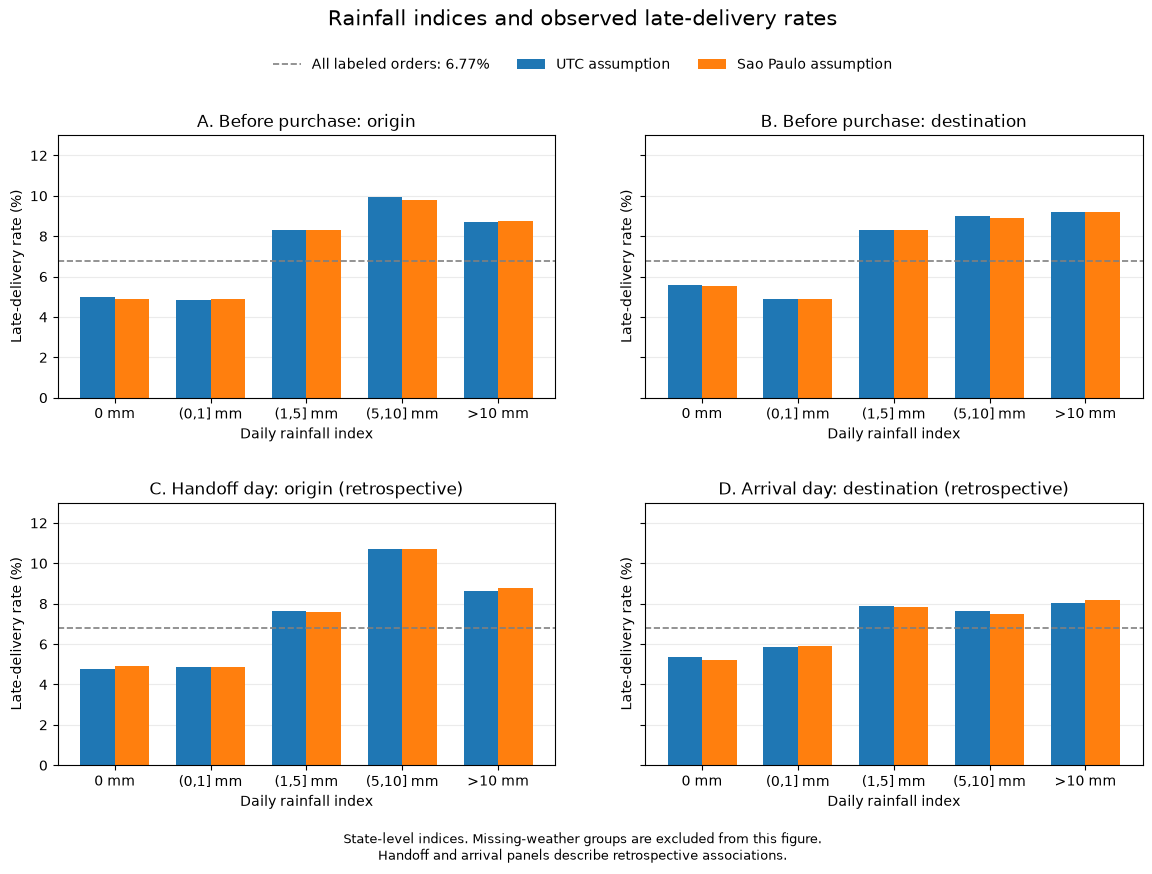

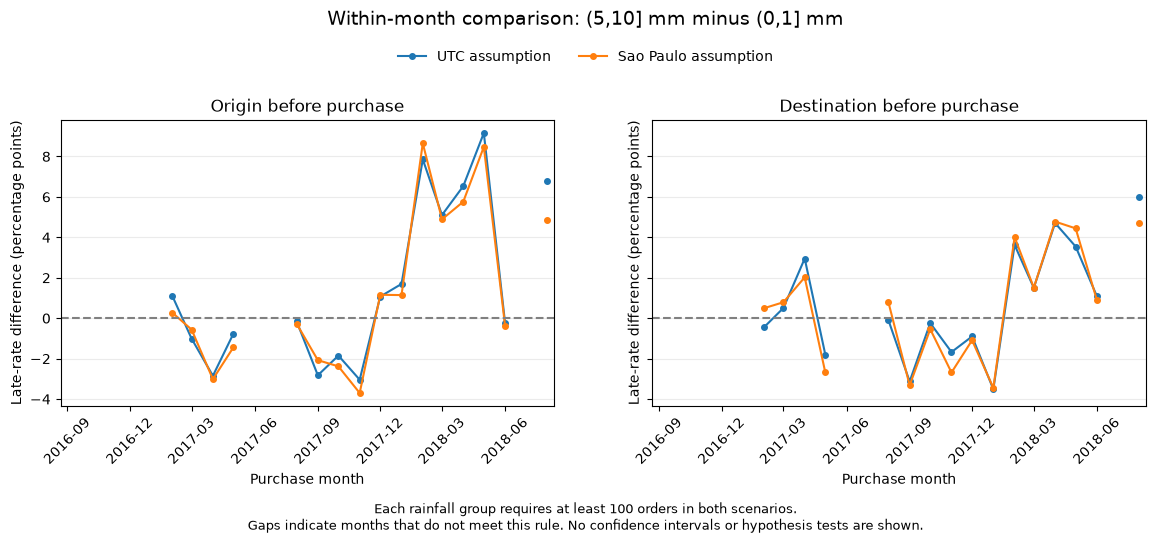

In [34]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

rain_results = pd.read_csv(
    weather_tables_dir / "weather_rain_band_summary.csv"
)

monthly_results = pd.read_csv(
    weather_tables_dir
    / "weather_rain_band_by_purchase_month.csv",
    dtype={"purchase_month": "string"},
)

class_balance = pd.read_csv(
    weather_tables_dir / "target_class_balance.csv"
)

overall_rate = float(
    class_balance.loc[
        class_balance["is_late"].eq(1),
        "labeled_percent",
    ].iloc[0]
)

figures_weather_dir = (
    PROJECT_ROOT / "outputs" / "figures" / "weather"
)
figures_weather_dir.mkdir(parents=True, exist_ok=True)

scenario_styles = {
    "assume_utc": ("UTC assumption", "#1f77b4"),
    "assume_sao_paulo": ("Sao Paulo assumption", "#ff7f0e"),
}

bands = [
    "0 mm",
    "(0,1] mm",
    "(1,5] mm",
    "(5,10] mm",
    ">10 mm",
]

context_titles = {
    "purchase_origin": "A. Before purchase: origin",
    "purchase_destination": "B. Before purchase: destination",
    "handoff_origin": "C. Handoff day: origin (retrospective)",
    "arrival_destination": (
        "D. Arrival day: destination (retrospective)"
    ),
}

# Figure 1: pooled rates by rainfall band.
fig_rain, axes = plt.subplots(
    2, 2, figsize=(14, 9), sharey=True
)

x = np.arange(len(bands))
width = 0.36

maximum_rate = rain_results.loc[
    rain_results["rain_band"].isin(bands),
    "late_rate_percent",
].max()

for ax, (context, title) in zip(
    axes.flat, context_titles.items()
):
    for index, (scenario, style) in enumerate(
        scenario_styles.items()
    ):
        label, color = style

        values = (
            rain_results.loc[
                rain_results["context"].eq(context)
                & rain_results["timezone_scenario"].eq(scenario)
            ]
            .set_index("rain_band")
            .reindex(bands)
        )

        ax.bar(
            x + (index - 0.5) * width,
            values["late_rate_percent"],
            width=width,
            color=color,
            label=label,
        )

    ax.axhline(
        overall_rate,
        color="gray",
        linestyle="--",
        linewidth=1.2,
        label=f"All labeled orders: {overall_rate:.2f}%",
    )

    ax.set_title(title)
    ax.set_xticks(x, bands)
    ax.set_xlabel("Daily rainfall index")
    ax.set_ylabel("Late-delivery rate (%)")
    ax.set_ylim(0, np.ceil(maximum_rate * 1.15))
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

handles, labels = axes.flat[0].get_legend_handles_labels()

fig_rain.suptitle(
    "Rainfall indices and observed late-delivery rates",
    fontsize=15,
    y=0.98,
)

fig_rain.legend(
    handles, labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.94),
    ncol=3,
    frameon=False,
)

fig_rain.subplots_adjust(
    top=0.84, bottom=0.14,
    hspace=0.40, wspace=0.18,
)

fig_rain.text(
    0.5, 0.035,
    "State-level indices. Missing-weather groups are excluded "
    "from this figure.\n"
    "Handoff and arrival panels describe retrospective associations.",
    ha="center",
    fontsize=9,
)

rain_figure_path = (
    figures_weather_dir / "rainfall_late_rate_by_context.png"
)

fig_rain.savefig(
    rain_figure_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

# Figure 2: monthly differences on common qualifying months.
fig_monthly, monthly_axes = plt.subplots(
    1, 2, figsize=(14, 5.5), sharey=True
)

calendar_months = pd.period_range(
    monthly_results["purchase_month"].min(),
    monthly_results["purchase_month"].max(),
    freq="M",
).astype(str)

calendar_dates = pd.to_datetime(
    calendar_months, format="%Y-%m"
)

pair_columns = pd.MultiIndex.from_product([
    list(scenario_styles),
    ["(0,1] mm", "(5,10] mm"],
])

for ax, context, title in zip(
    monthly_axes,
    ["purchase_origin", "purchase_destination"],
    ["Origin before purchase", "Destination before purchase"],
):
    selected = monthly_results.loc[
        monthly_results["context"].eq(context)
        & monthly_results["rain_band"].isin(
            ["(0,1] mm", "(5,10] mm"]
        )
    ]

    counts = selected.pivot(
        index="purchase_month",
        columns=["timezone_scenario", "rain_band"],
        values="valid_orders",
    ).reindex(columns=pair_columns)

    rates = selected.pivot(
        index="purchase_month",
        columns=["timezone_scenario", "rain_band"],
        values="late_rate_percent",
    ).reindex(columns=pair_columns)

    common_months = counts.ge(100).all(axis=1)

    for scenario, (label, color) in scenario_styles.items():
        difference = (
            rates[(scenario, "(5,10] mm")]
            - rates[(scenario, "(0,1] mm")]
        )

        difference = (
            difference.where(common_months)
            .reindex(calendar_months)
        )

        ax.plot(
            calendar_dates,
            difference.to_numpy(dtype=float),
            marker="o",
            markersize=4,
            linewidth=1.5,
            color=color,
            label=label,
        )

    ax.axhline(0, color="gray", linestyle="--")
    ax.set_title(title)
    ax.set_xlabel("Purchase month")
    ax.set_ylabel("Late-rate difference (percentage points)")
    ax.xaxis.set_major_locator(
        mdates.MonthLocator(interval=3)
    )
    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%Y-%m")
    )
    ax.set_xlim(
    calendar_dates.min() - pd.Timedelta(days=10),
    calendar_dates.max() + pd.Timedelta(days=10),
)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

fig_monthly.suptitle(
    "Within-month comparison: (5,10] mm minus (0,1] mm",
    fontsize=14,
    y=0.98,
)

handles, labels = monthly_axes[0].get_legend_handles_labels()

fig_monthly.legend(
    handles, labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.93),
    ncol=2,
    frameon=False,
)

fig_monthly.subplots_adjust(
    top=0.78, bottom=0.26, wspace=0.20
)

fig_monthly.text(
    0.5, 0.035,
    "Each rainfall group requires at least 100 orders in both "
    "scenarios.\n"
    "Gaps indicate months that do not meet this rule. "
    "No confidence intervals or hypothesis tests are shown.",
    ha="center",
    fontsize=9,
)

monthly_figure_path = (
    figures_weather_dir / "rainfall_within_month_comparison.png"
)

fig_monthly.savefig(
    monthly_figure_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

for path in [rain_figure_path, monthly_figure_path]:
    assert path.is_file()
    assert path.stat().st_size > 0
    print("Saved:", path.relative_to(PROJECT_ROOT))

plt.show()